PRIMERAAA PARTE!!!!!

**MACHINE LEARNING - RENDIMIENTO DE PAREJAS - ESPAÑA**

**OBJETIVO**: analizar el rendimiento de las parejas de jugadoras durante el campeonato del Eurobasket 2026 a partir de los datos obtenidos en los partidos.

**QuE hare?**

1. Clustering: identificar perfiles de parejas

2. Regresión regularizada: estudiar qué variables se relacionan con el rendimiento.

3. Random Forest: detectar qué variables tienen mayor importancia.

por último, un word explicativo para el entrenador y el staff. (Algo rápido-> entrenador)

las librerias que voy a usar

pandas + numpy -> manejar y calcular los datos

matplotlib -> es para las representaciones graficas

In [1]:
import os
#glob es para localizar y gestionar los archivos
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

par conectar con mi drive , acceder a los archivos guardados dentro de él

evito subirlos manualmente

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


defino ruta donde tengo guardado los csv de los diferentes partidos

se buscan automaticamente -> muestra los partidos encontrados

me aseguro que están

In [3]:
RUTA_DATASETS = "/content/drive/MyDrive/TFG_UGR/Proyecto_Parejas/Dataset_parejas"

archivos = glob.glob(os.path.join(RUTA_DATASETS, "*.csv"))

print("Número de partidos encontrados:", len(archivos))

for archivo in archivos:
    print(os.path.basename(archivo))

Número de partidos encontrados: 7
ESP_vs_C_131892.csv
ESP_vs_S_131905.csv
ESP_vs_E_131878.csv
ESP_vs_I_131897.csv
ESP_vs_M_131881.csv
ESP_vs_F_131919.csv
ESP_vs_T_131880.csv


quiero unir los 7 dataset en uno para analizarlos

añado tambien el partido de procedencia para identificar el encuentro.

en la nueva columna -> el partido de procedencia de cada registro

luego compruebo que la union se ha hecho OK  -> muestro : numero de partidos cargados , el numero de registros y las primeras filas del data set

In [4]:
lista_datasets = []

for archivo in archivos:

    df_partido = pd.read_csv(archivo)

    # guardo el nombre del partido
    df_partido["Partido"] = os.path.basename(archivo).replace(".csv", "")

    lista_datasets.append(df_partido)

#Uno tods los partidoos
df_total = pd.concat(lista_datasets, ignore_index=True)

print("Partidos cargados:", len(lista_datasets))
print("Registros totales:", len(df_total))

display(df_total.head())

Partidos cargados: 7
Registros totales: 361


,Jugadora 1,Jugadora 2,Min,PF,PC,+/-,Aro/min,Media/min,Triple/min,Finalizaciones PB/min,Partido
0,J11,J1,25.4,61,15,46,0.55,1.02,0.0,0.196464,ESP_vs_C_131892
1,J9,J1,21.7,53,11,42,0.55,1.06,0.0,0.184473,ESP_vs_C_131892
2,J11,J9,20.0,48,11,37,0.60,1.00,0.0,0.200334,ESP_vs_C_131892
3,J10,J7,12.6,37,8,29,0.63,1.19,0.0,0.237154,ESP_vs_C_131892
4,J11,J7,16.3,36,11,25,0.55,1.10,0.0,0.244898,ESP_vs_C_131892


**COMPROBACIÓN DEL DATASET**

VARIABLES EN FORMATO CORRECTO

compruebo : dimensiones del dataset

existencia de valores nulos

revisa el tipo de dato de cada variable , veo que las columnas numericas y de texto tienen el formato adecuado

In [5]:
print("Dimensiones:", df_total.shape)

print("\nValores nulos:")
print(df_total.isnull().sum())

print("\nTipos de variables:")
print(df_total.dtypes)

Dimensiones: (361, 11)

Valores nulos:
Jugadora 1               0
Jugadora 2               0
Min                      0
PF                       0
PC                       0
+/-                      0
Aro/min                  0
Media/min                0
Triple/min               0
Finalizaciones PB/min    0
Partido                  0
dtype: int64

Tipos de variables:
Jugadora 1                object
Jugadora 2                object
Min                      float64
PF                         int64
PC                         int64
+/-                        int64
Aro/min                  float64
Media/min                float64
Triple/min               float64
Finalizaciones PB/min    float64
Partido                   object
dtype: object


**PARA EL CLUSTERING** me interesa hacer una fila por pareja de jugadoras, con sus 7 partidos. Para estudiar el perfil global de cada pareja durante todo el campeonato (no en una actuación aislada)

**UTILIDAD PARA EL ENTRENADOR:** detectar qué parejas presentan perfiles similares y qué características diferencian unas combinaciones de otras.

ejemplo: una pareja que juega 2 min en un partido y 20 en otro no deberían de tener el mismo peso en ambos. y para las variables tampoco se pueden tratar por igual.

**TABLA UNICA**

-unificar las apariciones de cada pareja

-crear identificador único para evitar que cada pareja sea considerada diferente por el orden de las jugadoras

Objetivo: una única fila por pareja con su rendimiento acumulado.

In [6]:
# Crear identificador unico d pareja

df_total["Pareja"] = df_total.apply(
    lambda fila: " - ".join(
        sorted([fila["Jugadora 1"], fila["Jugadora 2"]])
    ),
    axis=1
)

# comprobacion
display(
    df_total[
        ["Jugadora 1", "Jugadora 2", "Pareja", "Partido"]
    ].head(10)
)

,Jugadora 1,Jugadora 2,Pareja,Partido
0,J11,J1,J1 - J11,ESP_vs_C_131892
1,J9,J1,J1 - J9,ESP_vs_C_131892
2,J11,J9,J11 - J9,ESP_vs_C_131892
3,J10,J7,J10 - J7,ESP_vs_C_131892
4,J11,J7,J11 - J7,ESP_vs_C_131892
5,J11,J12,J11 - J12,ESP_vs_C_131892
6,J10,J1,J1 - J10,ESP_vs_C_131892
7,J11,J10,J10 - J11,ESP_vs_C_131892
8,J1,J7,J1 - J7,ESP_vs_C_131892
9,J12,J1,J1 - J12,ESP_vs_C_131892


**RENDIMIENTO GLOBAL POR PAREJA**

agrupar los 7 partidos para obtener una fila.
las variables min, pf, pc y +- : acumulados

las zonas/min son ponderadas por los minutos jugados.

**ENTRENADOR:** conocer el perfil global de cada pareja y evita dar el mismo peso a una actuación de pocos minutos que a otra con mucha participación.

recupero los valores totales de cda zona ofensiva -> multiplicando las metricas por minuto  por los minutos jugados por cada pareja

Esto me deja hacer luego combinar correctamente las actuaciones de una misma pareja en diferentes partidos -> se tiene en cuenta el tiempo real en pista

In [7]:
#Recuperar ls valores acumulados de cada zona
df_total["Aro_total"] = df_total["Aro/min"] * df_total["Min"]
df_total["Media_total"] = df_total["Media/min"] * df_total["Min"]
df_total["Triple_total"] = df_total["Triple/min"] * df_total["Min"]
df_total["PB_total"] = df_total["Finalizaciones PB/min"] * df_total["Min"]

todos los registros se agrupan  a una misma pareja -> tengo una unica fila con un rendimiento durante el conjunto de partidos .

Se acumularan : los minutos, pf , pc , +- y las variables ofensivas de aro, media distancia, triple y poste bajo  + el numero de partidos en los que aparece la pareja

In [8]:
#Agrupar tods los partidos x pareja
df_global = df_total.groupby("Pareja").agg(
    Min=("Min", "sum"),
    PF=("PF", "sum"),
    PC=("PC", "sum"),
    PlusMinus=("+/-", "sum"),
    Aro_total=("Aro_total", "sum"),
    Media_total=("Media_total", "sum"),
    Triple_total=("Triple_total", "sum"),
    PB_total=("PB_total", "sum"),
    Partidos=("Partido", "nunique")
).reset_index()

calcular el rendimiento ofensivo por minuto de cada pareja con 4 variables: aro, media distancia, triple y poste bajo (PB)

si divido los valores acumulados entre los minutos totales -> obtengo un perfil ofensivo comparable entre parejas aunque hayan disputado diferentes tiempos en el partido.

ultimo -> selecciono las variables que voy a utilizar en el analisis y hago la tabla df_global  -> cada fila representa una pareja unica + rendimiento global

In [9]:
#rendimiento por min durante todo el campeonato
df_global["Aro/min"] = df_global["Aro_total"] / df_global["Min"]
df_global["Media/min"] = df_global["Media_total"] / df_global["Min"]
df_global["Triple/min"] = df_global["Triple_total"] / df_global["Min"]
df_global["PB/min"] = df_global["PB_total"] / df_global["Min"]

# Tabla que utilizare para continuar el analisis
df_global = df_global[
    ["Pareja", "Partidos", "Min", "PF", "PC", "PlusMinus",
     "Aro/min", "Media/min", "Triple/min", "PB/min"]
]

display(df_global.head(10))

print("Número de parejas únicas:", len(df_global))

,Pareja,Partidos,Min,PF,PC,PlusMinus,Aro/min,Media/min,Triple/min,PB/min
0,J1 - J10,7,75.5,141,80,61,1.047483,0.874185,0.013642,0.225065
1,J1 - J11,7,90.0,189,79,110,1.104011,0.700044,0.033811,0.211487
2,J1 - J12,5,48.4,90,49,41,0.867211,0.743409,0.000000,0.165274
3,J1 - J2,7,40.3,100,46,54,0.769007,1.064963,0.000000,0.148960
4,J1 - J4,6,32.9,71,38,33,1.400152,0.608176,0.030547,0.182222
5,J1 - J5,6,25.7,46,20,26,0.936187,0.702607,0.000000,0.116625
6,J1 - J6,7,46.9,100,60,40,1.344733,0.659936,0.000000,0.149210
7,J1 - J7,7,102.6,192,113,79,0.947778,0.721345,0.020097,0.204909
8,J1 - J8,5,65.2,112,66,46,1.241104,0.597853,0.031472,0.214825
9,J1 - J9,7,103.5,199,105,94,0.947343,0.753720,0.028386,0.183731


Número de parejas únicas: 65


**CLUSTRING DE PAREJAS**

¿existen diferentes perfiles de parejas según su rendimiento y las zonas desde donde lo generan?

**ENTRENADOR:** combinaciones con mayor impacto , parejas con más presencia por zonas.

qué variables usar? +- , aro/min, media/min, triple/min , pb/min

no uso ni los minutos ni los partidos

creo el x_cluster unicamente con las variables , dejo fuera los indicadores , minutos y numeros de partidos  para que no intervengan en la formacion de grupos

In [10]:
variables_cluster = [
    "PlusMinus",
    "Aro/min",
    "Media/min",
    "Triple/min",
    "PB/min"
]

X_cluster = df_global[variables_cluster].copy()

display(X_cluster.head())

,PlusMinus,Aro/min,Media/min,Triple/min,PB/min
0,61,1.047483,0.874185,0.013642,0.225065
1,110,1.104011,0.700044,0.033811,0.211487
2,41,0.867211,0.743409,0.000000,0.165274
3,54,0.769007,1.064963,0.000000,0.148960
4,33,1.400152,0.608176,0.030547,0.182222


tengo que **ESTANDARIZAR**

para que todas las variables tengan la misma escala comparable
y ninguna influya más enel clustering .

Standarscaler -> transforma los datos para que cada variable tenga aprox. 0 y desviacion estandar 1

In [11]:
from sklearn.preprocessing import StandardScaler

In [12]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_cluster)

print("Dimensiones para el clustering:", X_scaled.shape)

Dimensiones para el clustering: (65, 5)


ANTES DE KMEANS , de crear los grupos y quiero usar el METODO DEL CODO

**ELECCIÓN DEL NÚMERO DE CLUSTERS - METODO DEL CODO**

¿Cuántos perfiles diferentes de parejas parecen existir?

tengo que importar el Kmeans -> se usará para estudiar el numero adecuado de clusters + la agrupacion de parejas

comparo los diferentes numeros de grupos mediante su inercia y elijo una cantidad razonable de perfiles.

In [13]:
from sklearn.cluster import KMeans

ejecuto el kmeans con diferentes nº de clusters , desde el 1 hasta el 8 .

para cada nº de cluster calculo y almaceno la inercia -> mide la distancia interna de los datos respecto a los centros de sus grupos

-> asi puedo hacer el grafico del codo

In [14]:
inercias = []

valores_k = range(1, 9)

for k in valores_k:
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    modelo.fit(X_scaled)
    inercias.append(modelo.inertia_)

primer gráfico

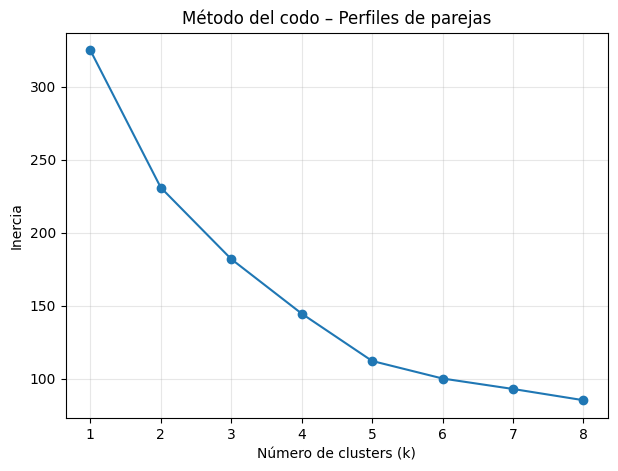

In [15]:
plt.figure(figsize=(7, 5))

plt.plot(valores_k, inercias, marker="o")

plt.xlabel("Número de clusters (k)")
plt.ylabel("Inercia")
plt.title("Método del codo – Perfiles de parejas")

plt.grid(alpha=0.3)
plt.show()

la caida es muy fuerte en k=1 y k=2 , continúa bajando hasta k=5.

El codo debe de estar entre k=4 y k=5 (aunque no es un codo muy marcado)

como no estoy muy segura, el método del codo sugiere 4-5 grupos.

**USO METODO DE SILHOUETTE SCORE:** cuanto mayor sea el valor, mejor separados y más coherentes son los grupos.

In [16]:
from sklearn.metrics import silhouette_score

resultados_silhouette = []

for k in range(2, 7):
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    etiquetas = modelo.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, etiquetas)

    resultados_silhouette.append([k, score])

df_silhouette = pd.DataFrame(
    resultados_silhouette,
    columns=["Clusters", "Silhouette"]
)
display(df_silhouette)

,Clusters,Silhouette
0,2,0.286181
1,3,0.257062
2,4,0.280876
3,5,0.313232
4,6,0.266546


el mejor es el 5 con 0,313232. Encaja con lo del método del codo.

**HARÉ 5 PERFILES DE PAREJAS**

In [17]:
# moodelo definitivo de clustering

kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

df_global["Cluster"] = kmeans.fit_predict(X_scaled)

# Numero de parejas en cada cluster
print(df_global["Cluster"].value_counts().sort_index())

Cluster
0    12
1     6
2    15
3    24
4     8
Name: count, dtype: int64


Que caracteriza a cada pareja de cada cluster? calculo la media de las variables que se usan para agruparlas. Así veo si el cluster destaca en aro/media distancia....

asi puedo conocer que caracteristicas predominan en cada grupo y entiendo que tipo de perfil de pareja representa cada cluster .

redondeo los valores medios y así comparar de una forma sencilla las diferencias de rendimientos entre los 5 perfiles

In [18]:
#perfil medio d cada cluster
variables_cluster = [
    "Aro/min",
    "Media/min",
    "Triple/min",
    "PB/min",
    "PlusMinus"
]

perfil_clusters = (
    df_global
    .groupby("Cluster")[variables_cluster]
    .mean()
    .round(3)
)

display(perfil_clusters)

,Aro/min,Media/min,Triple/min,PB/min,PlusMinus
Cluster,,,,,
0,1.303,0.615,0.014,0.214,35.167
1,0.704,1.367,0.000,0.056,15.333
2,0.801,0.834,0.001,0.206,33.600
3,1.058,0.778,0.026,0.230,75.375
4,0.906,0.666,0.051,0.103,42.875


**cluster 0 - Ataque aro :** 1,303 /min ,

**cluster 1 - media distancia:** tiene mayor media/min 1,367

**cluster 2 - equilibrado:** aro y media bastante similares, con presencia importante en pb. (no domina claramente una zona)

**cluster 3 - interior + alto rendimiento:** tiene alto el aro/min (1,058) , tiene el plus minus más alto 75,375. PERFIL DE JUEGO INTERIOR

**cluster 4 - mayor presencia exterior:** no significa que sean tiradores de triples porque es pequeño pero comparativamente es el cluster con mayor triple/min

In [19]:
#Parejas pertenecientes cada cluster

parejas_por_cluster = df_global[
    ["Pareja", "Cluster", "Partidos", "Min", "PlusMinus",
     "Aro/min", "Media/min", "Triple/min", "PB/min"]
].sort_values(
    by=["Cluster", "PlusMinus"],
    ascending=[True, False]
)

display(parejas_por_cluster)

,Pareja,Cluster,Partidos,Min,PlusMinus,Aro/min,Media/min,Triple/min,PB/min
25,J11 - J6,0,7,58.4,64,1.282209,0.666575,0.000000,0.256961
8,J1 - J8,0,5,65.2,46,1.241104,0.597853,0.031472,0.214825
22,J11 - J3,0,7,27.8,46,1.291655,0.682050,0.000000,0.322741
27,J11 - J8,0,5,35.1,43,1.427977,0.486752,0.056182,0.313640
24,J11 - J5,0,6,29.6,42,1.318176,0.676419,0.000000,0.135009
...,...,...,...,...,...,...,...,...,...
58,J5 - J9,4,6,31.1,42,0.774727,0.736431,0.031383,0.096549
48,J3 - J8,4,5,22.9,38,0.874760,0.783319,0.043231,0.087763
54,J4 - J9,4,5,13.2,33,0.832879,0.301667,0.075152,0.075758
42,J2 - J8,4,5,27.4,32,0.911934,0.692847,0.035730,0.109019


**VISUALIZAR LOS PERFILES DE LOS CLUSTERS**

ahora selecciono mis 4 variables con las zonas de juego

comparo visualmente los perfiles obtenidos en el kmeans

El grafico de barras -> veré que zonas tienen mayor presencia en cada cluster y me facilitará la interpretación de los perfiles

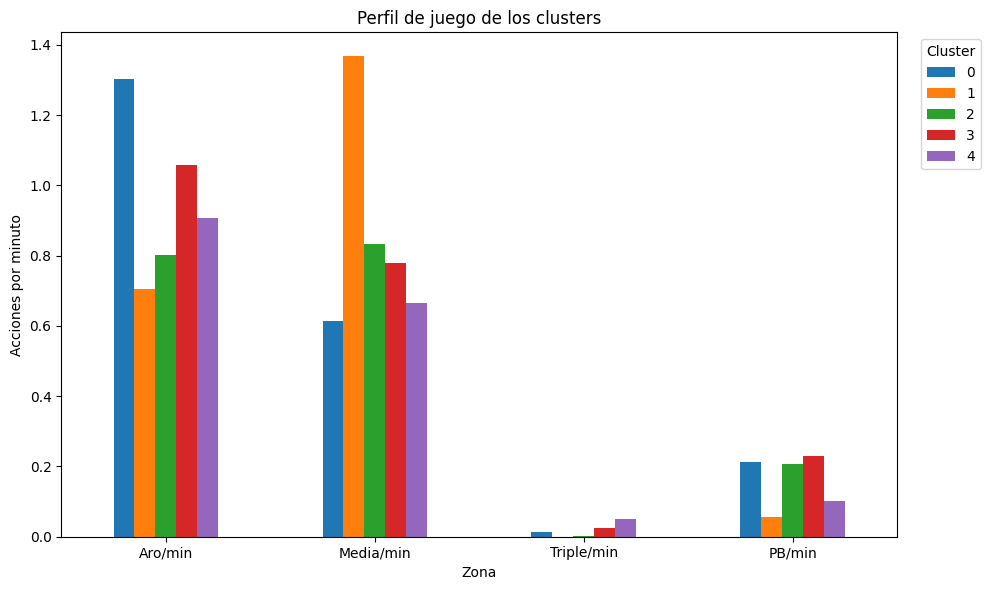

In [20]:
#variables de juego que quiero comparar
zonas = ["Aro/min", "Media/min", "Triple/min", "PB/min"]

# transposicon de la tabla para facilitar la representacion
perfil_zonas = perfil_clusters[zonas].T

#grafica
ax = perfil_zonas.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Perfil de juego de los clusters")
plt.xlabel("Zona")
plt.ylabel("Acciones por minuto")
plt.xticks(rotation=0)

plt.legend(
    title="Cluster",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

para leerlo (elijo un cluster y recorro las zonas) . Ejemplo , el cluster 0 -> miro aro -> media -> triple -> pb

recordar al interpretar la gráfica que lo miro por los colores de las barras, cluster cero es la barra azul y veo la presencia en las zonas.

**cluster 0:** dominio de ataque aro.

**clustr 1:** media distancia

**cluster 2:** perfil equilibrado, sin zona dominante

**cluster 3:** interior + PB ALTO  +-

**cluster 4:** mayor presencia en exterior .

In [21]:
nombres_cluster = {
    0: "Ataque al aro",
    1: "Media distancia",
    2: "Equilibrado",
    3: "Interior + PB",
    4: "Mayor presencia exterior"
}

df_global["Perfil"] = df_global["Cluster"].map(nombres_cluster)

display(
    df_global[
        ["Pareja", "Perfil", "Partidos", "Min", "PlusMinus",
         "Aro/min", "Media/min", "Triple/min", "PB/min"]
    ].head(10)
)

,Pareja,Perfil,Partidos,Min,PlusMinus,Aro/min,Media/min,Triple/min,PB/min
0,J1 - J10,Interior + PB,7,75.5,61,1.047483,0.874185,0.013642,0.225065
1,J1 - J11,Interior + PB,7,90.0,110,1.104011,0.700044,0.033811,0.211487
2,J1 - J12,Equilibrado,5,48.4,41,0.867211,0.743409,0.000000,0.165274
3,J1 - J2,Equilibrado,7,40.3,54,0.769007,1.064963,0.000000,0.148960
4,J1 - J4,Ataque al aro,6,32.9,33,1.400152,0.608176,0.030547,0.182222
5,J1 - J5,Equilibrado,6,25.7,26,0.936187,0.702607,0.000000,0.116625
6,J1 - J6,Ataque al aro,7,46.9,40,1.344733,0.659936,0.000000,0.149210
7,J1 - J7,Interior + PB,7,102.6,79,0.947778,0.721345,0.020097,0.204909
8,J1 - J8,Ataque al aro,5,65.2,46,1.241104,0.597853,0.031472,0.214825
9,J1 - J9,Interior + PB,7,103.5,94,0.947343,0.753720,0.028386,0.183731


MEJORES PAREJAS DE CADA PERFIL - TOP 3

ordeno las parejas dentro de cada perfil por el plus /minus , de mayor a menor y selecciono las 3 primeras de cada grupo .

Así veré que parejas destacan dentro de cada estilo de juego, manteniendo además sus minutos, partidos y demás metricas

In [22]:
top3_por_perfil = (
    df_global
    .sort_values(
        by=["Perfil", "PlusMinus"],
        ascending=[True, False]
    )
    .groupby("Perfil")
    .head(3)
    [
        ["Perfil", "Pareja", "Partidos", "Min", "PlusMinus",
         "Aro/min", "Media/min", "Triple/min", "PB/min"]
    ]
)

display(top3_por_perfil)

,Perfil,Pareja,Partidos,Min,PlusMinus,Aro/min,Media/min,Triple/min,PB/min
25,Ataque al aro,J11 - J6,7,58.4,64,1.282209,0.666575,0.000000,0.256961
8,Ataque al aro,J1 - J8,5,65.2,46,1.241104,0.597853,0.031472,0.214825
22,Ataque al aro,J11 - J3,7,27.8,46,1.291655,0.682050,0.000000,0.322741
3,Equilibrado,J1 - J2,7,40.3,54,0.769007,1.064963,0.000000,0.148960
11,Equilibrado,J10 - J12,5,48.4,49,0.829215,0.911116,0.000000,0.206956
17,Equilibrado,J10 - J7,6,55.9,49,1.033578,0.913864,0.000000,0.232128
51,Interior + PB,J4 - J6,7,86.7,113,1.198870,0.809481,0.011903,0.230949
1,Interior + PB,J1 - J11,7,90.0,110,1.104011,0.700044,0.033811,0.211487
44,Interior + PB,J3 - J4,7,70.0,104,1.098114,0.844214,0.014286,0.257619
43,Mayor presencia exterior,J2 - J9,7,50.8,74,0.848878,0.767677,0.040433,0.098549


**CONTROL DE MUESTRA**

¿tengo suficientes minutos para considerar representativo el rendimiento de una pareja?  tengo que diferenciar las parejas con una muestra suficiente de aquellas que han compartido pocos minutos.

Evito considerar como "mejor pareja" una combinación cuyo buen rendimiento procede de pocos minutos de juego.

voy a considerar 20 min de umbral (se puede modificar)

cada pareja se clasifica como suficiente si alcanza al menos 20 minutos y como reducida si queda por debajo.

Asi evito interpretar como relevante el rendimiento de una preja cuando sus resultados proceden de muy pocos minutos compartidos, aportando + contexto al analisis del +- y los perfiles de los cluster

In [23]:
#umbral minimo de minutos
MIN_MINUTOS = 20

df_global["Muestra"] = np.where(
    df_global["Min"] >= MIN_MINUTOS,
    "Suficiente",
    "Reducida"
)

print(df_global["Muestra"].value_counts())

display(
    df_global[
        ["Pareja", "Perfil", "Partidos", "Min", "PlusMinus", "Muestra"]
    ].sort_values("Min", ascending=False)
)

Muestra
Suficiente    53
Reducida      12
Name: count, dtype: int64


,Pareja,Perfil,Partidos,Min,PlusMinus,Muestra
9,J1 - J9,Interior + PB,7,103.5,94,Suficiente
7,J1 - J7,Interior + PB,7,102.6,79,Suficiente
1,J1 - J11,Interior + PB,7,90.0,110,Suficiente
63,J7 - J9,Interior + PB,7,87.6,64,Suficiente
51,J4 - J6,Interior + PB,7,86.7,113,Suficiente
...,...,...,...,...,...,...
31,J12 - J4,Equilibrado,1,9.6,14,Reducida
15,J10 - J5,Media distancia,4,9.0,13,Reducida
32,J12 - J5,Media distancia,2,6.8,9,Reducida
29,J12 - J2,Media distancia,2,6.1,14,Reducida


guardar tabla para powerbi

In [24]:
ruta_salida = "/content/drive/MyDrive/TFG_UGR/Proyecto_ML_Parejas_UGR/ML_powerbi_ugr"

os.makedirs(ruta_salida, exist_ok=True)

df_global.to_csv(
    os.path.join(ruta_salida, "clustering_parejas_U18_2026.csv"),
    index=False
)

print("Tabla de clustering guardada correctamente.")


Tabla de clustering guardada correctamente.


**RENDIMIENTO MEDIO POR PERFIL**

¿que perfil de pareja presenta mejor rendimiento global? comparo el +- medio de los 5 perfiles creados por el clustering

ordeno los perfiles de mayor a menor plus /minus medio y lo represento mediante el grafico de barras

compruebo -> diferentes estilos de juego identificados por kmeans presentan diferencias a su rendimiento global + que tipo de perfil está asociado a un mayor impacto en el marcador

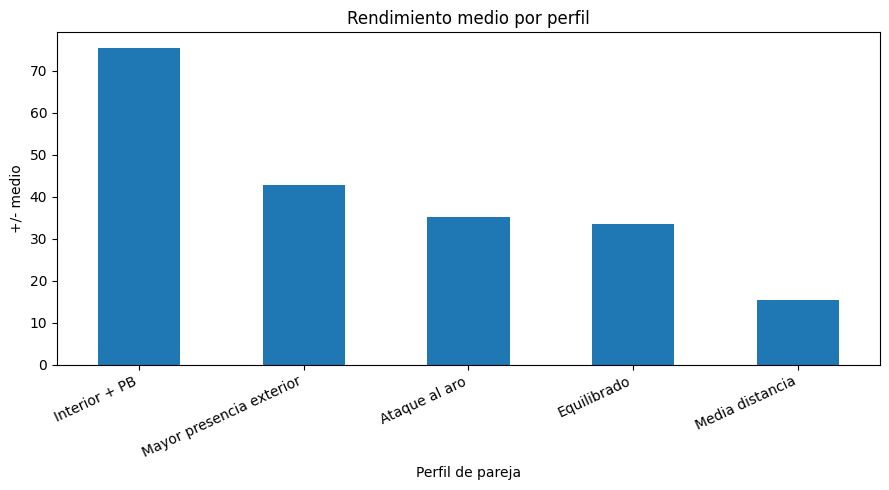

In [25]:
#plusMinus medio x perfil

rendimiento_perfiles = (
    df_global
    .groupby("Perfil")["PlusMinus"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))

rendimiento_perfiles.plot(
    kind="bar"
)

plt.title("Rendimiento medio por perfil")
plt.xlabel("Perfil de pareja")
plt.ylabel("+/- medio")
plt.xticks(rotation=25, ha="right")

plt.tight_layout()

# Guardar grafica
ruta_graficos = "/content/drive/MyDrive/TFG_UGR/Proyecto_ML_Parejas_UGR/ML_graficos"

plt.savefig(
    ruta_graficos + "/rendimiento_medio_por_perfil.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

**IMPORTANTE:** +- representa asociacion con el rendimiento observado, no causalidad. Un perfil con mayor +- no implica que ese estilo provoque directamente un mejor resultado

**TOP 3 DE PAREJAS POR PERFIL**

ordeno las parejas de cada perfil de juego segun su plus/minus de mayor a menor

a continuacion, se selecciona las tres parejas con mayor plus minus dentro de cada perfil -> identifico las combinaciones que destacan

creo una etiqueta -> nombre de pareja + perfil

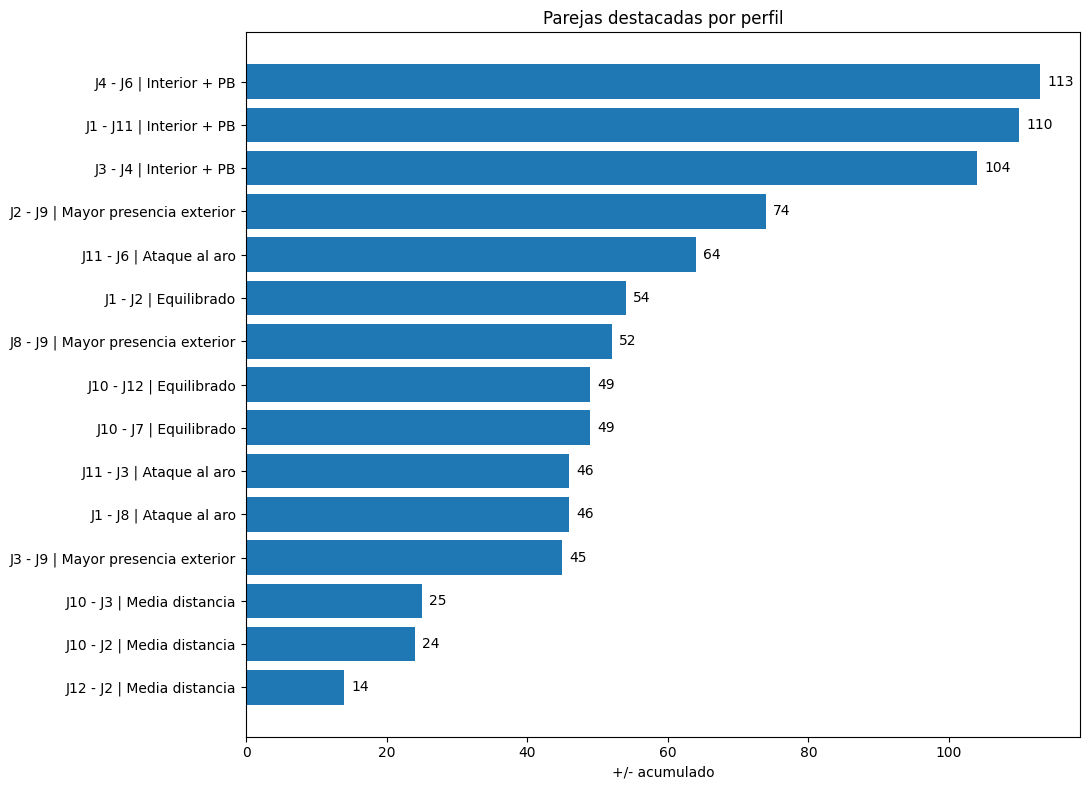

In [26]:
# Top3 parejas x perfil
top3_grafico = (
    df_global
    .sort_values(
        by=["Perfil", "PlusMinus"],
        ascending=[True, False]
    )
    .groupby("Perfil")
    .head(3)
    .copy()
)

# Etiqueta con pareja + perfil
top3_grafico["Etiqueta"] = (
    top3_grafico["Pareja"] +
    " | " +
    top3_grafico["Perfil"]
)

# Ordeno para el grafico
top3_grafico = top3_grafico.sort_values(
    "PlusMinus",
    ascending=True
)

plt.figure(figsize=(11, 8))

bars = plt.barh(
    top3_grafico["Etiqueta"],
    top3_grafico["PlusMinus"]
)

#Valor al final de cada barra
for bar, valor in zip(bars, top3_grafico["PlusMinus"]):
    plt.text(
        valor + 1,
        bar.get_y() + bar.get_height()/2,
        f"{valor:.0f}",
        va="center"
    )

plt.title("Parejas destacadas por perfil")
plt.xlabel("+/- acumulado")
plt.ylabel("")


plt.tight_layout()

ruta_graficos = "/content/drive/MyDrive/TFG_UGR/Proyecto_ML_Parejas_UGR/ML_graficos"

os.makedirs(ruta_graficos, exist_ok=True)

plt.savefig(
    ruta_graficos + "/parejas_destacadas_por_perfil.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**REGRESIÓN LINEAL - ¿QUE INFLUYE EN EL RENDIMIENTO?**

que caracteristicas del juego de una pareja están relacionadas con su rendimiento? tengo que estudiar el juego por cada zona y relacionarlo con el +- de las parejas

entrenador: ayuda a detectar qué zonas de juego están más asociadas con un mejor rendimiento de las parejas.

el objetivo es (y) -> +-

variables explicativas (x) : aro/min, media/min, triple / min y pb/min

In [27]:
#Variables q describen el perfil de juego
variables_regresion = [
    "Aro/min",
    "Media/min",
    "Triple/min",
    "PB/min"
]

X = df_global[variables_regresion]

#Variable q quiero explicar
y = df_global["PlusMinus"]

print("Variables utilizadas:")
print(variables_regresion)

print("\nNúmero de parejas:", len(X))

Variables utilizadas:
['Aro/min', 'Media/min', 'Triple/min', 'PB/min']

Número de parejas: 65


**ENTRENAMIENTO Y PRUEBA**

con entrenamiento el modelo aprende las relaciones entre las variables.

con la prueba comprueba cómo funciona con datos que no ha utilizado para aprender

In [28]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Parejas para entrenamiento:", len(X_train))
print("Parejas para prueba:", len(X_test))

Parejas para entrenamiento: 52
Parejas para prueba: 13


entreno el modelo con las 52 parejas y evaluo la capacidad para explicar el +- en las parejas de prueba

el **R^2 indica cuánto del compartamiento del +- consigue explicar el modelo**.
MAE  indica , de media, cuánto se alejan las prediciones del +- real.    

In [29]:
#entrenar modelo
modelo_regresion = LinearRegression()

modelo_regresion.fit(X_train, y_train)

# Prediccion sobre las parejas de prueba
y_pred = modelo_regresion.predict(X_test)

#evaluacion
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print("R²:", round(r2, 3))
print("MAE:", round(mae, 2))

R²: 0.392
MAE: 15.22


R^2 -> 0,392 las cuatro variables de zona explican aproximadamente un 39,2% de la variacion del +-

MAE 15,22 las predicciones se desvían, de media, unos 15 puntos de +- respecto del valor real

**INTERESANTE:** el rendimiento de una pareja no se explica bien únicamente por dónde finaliza.

**Tiene sentido en baloncesto:** el +- también depende de defensa, rival, contexto, minutos compartidos, pérdidas, rebotes...

**No significa que la regresión haya salido mal.**

El modelo nos está mostrando que la relación lineal entre estas cuatro variables y el +- es débil. También es un resultado.

**Refuerza mi decisión de que el clustering sea el protagonista** , las zonas parecen servir mejor para identificar perfiles de juego que para predecir directamente el rendimiento.

**RANDOM FOREST**

Quiero ver si un modelo no lineal consigue explicar el +- mejor que la regresion lineal

In [30]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

# Modelo RandomForest
rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Entrenamiento
rf.fit(X_train, y_train)

# Predicion
y_pred_rf = rf.predict(X_test)

#evaluacion
r2_rf = r2_score(y_test, y_pred_rf)
mae_rf = mean_absolute_error(y_test, y_pred_rf)

print("R² Random Forest:", round(r2_rf, 3))
print("MAE Random Forest:", round(mae_rf, 2))

R² Random Forest: 0.368
MAE Random Forest: 17.44



no hay información suficiente para predecir el rendimiento global de una pareja.

conclusion: el analisis muestra que las zonas de juego aportan informacion sobre el rendimiento de las parejas, pero NO son suficientes para explicarlo por complejo .

IMPORTANTE!!!

La regresión consigue explicar ->  parte del plus/minus, aunque mantiene un error considerable.

->Esto indica:  que el rendimiento depende también de otros factores del juego y justifica comparar con un modelo no lineal como el Random Forest.


**word automatico**

necisto la libreria python docx -> documento de word

importo las herramientas necesarias para crear y dar formato

In [31]:
!pip install python-docx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.0/253.0 kB 5.5 MB/s eta 0:00:00


pongo funciones para dar formato : tamaños, alineacion, secciones y elementos internos del word

importa os -> trabajar con rutas y archivos

In [32]:
from docx import Document
from docx.shared import Inches, Pt
from docx.enum.text import WD_ALIGN_PARAGRAPH
from docx.enum.section import WD_SECTION
from docx.oxml import OxmlElement
from docx.oxml.ns import qn

import os

añado las rutas

In [33]:
RUTA_PROYECTO = "/content/drive/MyDrive/TFG_UGR/Proyecto_ML_Parejas_UGR"
RUTA_GRAFICOS = f"{RUTA_PROYECTO}/ML_graficos"

RUTA_LOGO = "/content/drive/MyDrive/TFG_UGR/Proyecto_Parejas/Logo.png"

RUTA_RENDIMIENTO = f"{RUTA_GRAFICOS}/rendimiento_medio_por_perfil.png"
RUTA_PAREJAS = f"{RUTA_GRAFICOS}/parejas_destacadas_por_perfil.png"


RUTA_INFORME = f"{RUTA_PROYECTO}/Informe_Clustering_U18_2026.docx"

añado los margenes convenientes

In [34]:
from docx import Document
from docx.shared import Inches, Pt
from docx.enum.text import WD_ALIGN_PARAGRAPH
from docx.enum.section import WD_SECTION

doc = Document()

# Margenes para aprovechar bien una sola pag
section = doc.sections[0]
section.top_margin = Inches(0.4)
section.bottom_margin = Inches(0.4)
section.left_margin = Inches(0.55)
section.right_margin = Inches(0.55)

creo la cabecera con el logo

In [35]:
# CABECERA
header = section.header
p = header.paragraphs[0]
p.alignment = WD_ALIGN_PARAGRAPH.CENTER

p.add_run().add_picture(RUTA_LOGO, width=Inches(0.85))

p.add_run(
    "\nEUROBASKET 2026 · SELECCIÓN ESPAÑOLA U18 FEMENINA"
).bold = True

pongo el titulo

In [36]:
# TITULO
p = doc.add_paragraph()
p.alignment = WD_ALIGN_PARAGRAPH.CENTER

run = p.add_run("ANÁLISIS DE PAREJAS · CLUSTERING")
run.bold = True
run.font.size = Pt(16)

In [37]:
#GRAFICA1
p = doc.add_paragraph()
p.alignment = WD_ALIGN_PARAGRAPH.CENTER
p.add_run().add_picture(
    RUTA_RENDIMIENTO,
    width=Inches(6.7)
)

# GRAFICA2
p = doc.add_paragraph()
p.alignment = WD_ALIGN_PARAGRAPH.CENTER
p.add_run().add_picture(
    RUTA_PAREJAS,
    width=Inches(6.7)
)

necesito una leyenda explicativa

In [38]:
# LEYENDA
p = doc.add_paragraph()

run = p.add_run("PERFILES DE PAREJA\n")
run.bold = True
run.font.size = Pt(10)

texto = (
    "Interior + PB · Mayor presencia en aro y poste bajo\n"
    "Ataque al aro · Alta presencia de finalizaciones cercanas\n"
    "Media distancia · Mayor peso de finalizaciones de media distancia\n"
    "Mayor presencia exterior · Mayor utilización del tiro exterior\n"
    "Equilibrado · Distribución más compensada entre las distintas zonas"
)

run = p.add_run(texto)
run.font.size = Pt(8.5)

guardo el documento

In [39]:
doc.save(RUTA_INFORME)

print("Informe creado correctamente:")
print(RUTA_INFORME)

Informe creado correctamente:
/content/drive/MyDrive/TFG_UGR/Proyecto_ML_Parejas_UGR/Informe_Clustering_U18_2026.docx


**SEGUNDA PARTE: jugadoras como particulas**

**¿Podemos interpretar las parejas de jugadoras como particulas dentro de un espacio de caracteristicas?**

**¿y estudiar sus interacciones mediante un modelo inspirado en la fisica?**

quiero ver si una representacion inspirada en sistemas de particula me permite -> estudiar similitud, proximidad e interacción entre perfiles de parejas -> luego lo comparo con los clusters

Cada pareja como una particula situada en el espacio de caracteristicas.  

Su posición no representa una posicion fisica en la cancha, sino su comportamiento segun las variables : aro/min, media distancia/min , triple/min  y poste bajo /min

2 parejas con comportamientos similares estarán próximas en este espacio, mientras que parejas con perfiles diferentes estarán alejadas

Luego construyo un potencial de interaccion inspirado en Lennard-Jones

**¿puede un modelo inspirado en la interaccion de particulas ayudarme a identificar relaciones y estructuras entre las parejas que sean coherentes con los perfiles de kmeans?**

no estoy estudiando una distancia fisica real entre jugadoras -> sino una distancia matemática en un espacio de caracteristicas

interpretacion fisica-> igual que un sistema de particulas su comportamiento depende de su posicion relativa -> uso la distancia entre parejas para construir una funcion de interaccion

**PREPARACION DEL ESPACIO FISICO**

Para construir el modelo fisico seleciono 4 variables que describen el comportamiento ofensivo de cada pareja: aro, media distancia, triple y el poste bajo por minuto. -> luego me definen la posicion de cada pareja dentro del espacio.

In [40]:
# Variables que definiran el espacio ofensivo
variables_fisica = [
    "Aro/min",
    "Media/min",
    "Triple/min",
    "PB/min"
]

#datos de las parejas
X_fisica = df_global[variables_fisica].copy()

print("Número de parejas:", len(X_fisica))
print("Variables del espacio:", variables_fisica)

X_fisica.head()

Número de parejas: 65
Variables del espacio: ['Aro/min', 'Media/min', 'Triple/min', 'PB/min']


,Aro/min,Media/min,Triple/min,PB/min
0,1.047483,0.874185,0.013642,0.225065
1,1.104011,0.700044,0.033811,0.211487
2,0.867211,0.743409,0.000000,0.165274
3,0.769007,1.064963,0.000000,0.148960
4,1.400152,0.608176,0.030547,0.182222


se definen-> 65 parejas como elementos de un espacio ofensivo de 4 dimensiones.

cada coordenada-> representa un comportamiento por minuto en una zona de juego

mi base -> para interpretar las parejas como particulas + poder estudiar las distancias

**NORMALIZACION + construccion de parejas como particulas**

tengo que transformar las 4 variables en una misma escala

normalizo las variables ofensivas para que todas contribuyan de forma comparable -> uso StandarScaler (centra cada variable respecto a su medida y la expresa en funcion de su desviacion estandar)

In [41]:
from sklearn.preprocessing import StandardScaler

#Normalizacion de las variables
scaler_fisica = StandardScaler()

X_fisica_norm = scaler_fisica.fit_transform(X_fisica)

print("Dimensiones del espacio normalizado:", X_fisica_norm.shape)
print("\nPrimera pareja normalizada:")
print(X_fisica_norm[0])

Dimensiones del espacio normalizado: (65, 4)

Primera pareja normalizada:
[ 0.22318995  0.32307619 -0.25815824  0.47481828]


dimensiones -> 65 parejas y 4 variables

los valores negativos no son un mal rendimiento -> la variable esta por debajo de la media del conjunto -> los positivos están por encima

interpreto cada pareja de jugadoras como una particula situada en el espacion ofensivo. La posicion de cada particula viene definida por las 4 coordenadas.

In [42]:
import pandas as pd

# Creo el espacio de partiiculas
particulas = pd.DataFrame(
    X_fisica_norm,
    columns=["Aro_norm", "Media_norm", "Triple_norm", "PB_norm"]
)

#Asocio cada partcula con su pareja
particulas.insert(0, "Pareja", df_global["Pareja"].values)

print("Número de partículas:", len(particulas))
display(particulas.head())

Número de partículas: 65


,Pareja,Aro_norm,Media_norm,Triple_norm,PB_norm
0,J1 - J10,0.223190,0.323076,-0.258158,0.474818
1,J1 - J11,0.452683,-0.448294,0.776158,0.293531
2,J1 - J12,-0.508686,-0.256207,-0.957783,-0.323440
3,J1 - J2,-0.907375,1.168139,-0.957783,-0.541250
4,J1 - J4,1.654964,-0.855231,0.608770,-0.097180


es como si hubiese obtenido el r(j1-j10) = (0.223 , 0.323 , -0.258 , 0.475)

es como si tuviese (Aro, media, Triple, PB)-> (C1, C2, C3, C4)
LAS 4 C COMPONENTES.

**PARA VISUALIZAR EL ESPACIO OFENSIVO**

**PROBLEMA**: estoy en un espacio 4D , para poder visualizarlo haré lo siguiente:

**espacio real del modelo 4D** -> con esto calculo luego las distancias y el potencial tipo Lennard-Jones.

**Visualizacion 2D** : con las dos primeras componentes C1-C2

**Visualizacion 3D** : c1, c2,c3  

**REDUCCION DE 4D A 2D**

tengo que importar la herramienta pca de skearn que es el principal component analysis . Es para reducir el nº de variables intentando perder la menor cantidad posible de informacion

c1 recoge la mayor variabilidad posible de los datos

c2 recoge la mayor parte posible de lo que queda, siendo independiente de c1
y esto es sucesivamente.

explained_variance_ratio me devuelva la varianza explciada como proprocion entre 0 y 1

In [43]:
from sklearn.decomposition import PCA

#reduzco el espacio 4D a 2D para visualizarlo
pca_2d = PCA(n_components=2)

X_pca_2d = pca_2d.fit_transform(X_fisica_norm)

print("Dimensiones originales:", X_fisica_norm.shape)
print("Dimensiones para visualización:", X_pca_2d.shape)

print(
    "Varianza explicada por C1 y C2:",
    round(pca_2d.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

Dimensiones originales: (65, 4)
Dimensiones para visualización: (65, 2)
Varianza explicada por C1 y C2: 75.11 %


La varianza -> es del 75 %  solo con c1 y c2 se conserva casi 3/4 de la información .
Así que conservo el 75,11% de la variabilidad total. La representacion en 2D va a mantener una parte importante de la estructura original de los datos.

importante!! c1 y c2 son ahora una combinacion de las variabls originales.

es decir, combino -> aro/min + media/min y  triple/min + pb/min

**REPRESENTACION 2D**

cada pareja es representada como una particula dentro del espacio reducido.
Las coordenadas c1 y c2 resumen las 4 variables ofensivas originales y ya podemos ver que parejas presentan comportamientos similares/diferentes

con x_pca_2d [:,0] selecciono la primera componente de todas las parejas
y con la de abajo selecciono la segunda componente

con plt.scatter (C1,c2) dibujo la pareja como un punto

c1 en el eje x

c2 en el eje y

enumerate recorre todas las parejas

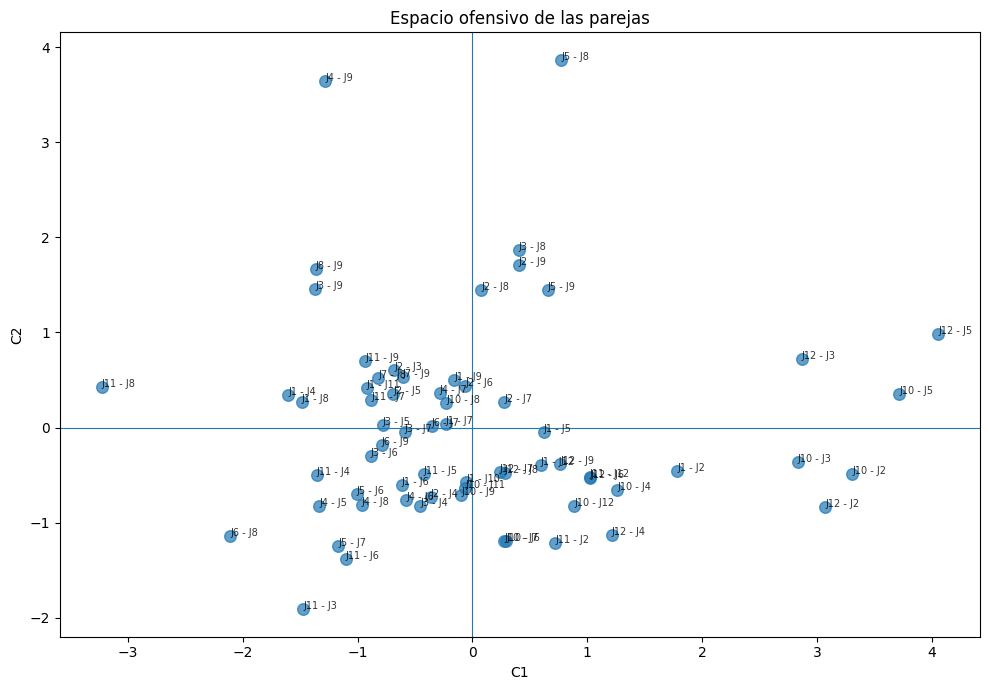

In [44]:
import matplotlib.pyplot as plt

#coordenadas de cada pareja en el espacio reducido
C1 = X_pca_2d[:, 0]
C2 = X_pca_2d[:, 1]

plt.figure(figsize=(10, 7))

plt.scatter(
    C1,
    C2,
    s=70,
    alpha=0.7
)

# Etiqueto cada particula con su pareja
for i, pareja in enumerate(df_global["Pareja"]):
    plt.annotate(
        pareja,
        (C1[i], C2[i]),
        fontsize=7,
        alpha=0.8
    )

plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)

plt.xlabel("C1")
plt.ylabel("C2")
plt.title("Espacio ofensivo de las parejas")

plt.tight_layout()
plt.show()

interpretacion: las parejas próximas representan perfiles ofensivos similares

una mayor separacion -> diferencias en su comportamiento.

**REDUCCION DE ESPACIO DE 4D A 3D**

aplico pca para reducir de 4 a 3 variables y asi represento las parejas en 3D

In [45]:
from sklearn.decomposition import PCA

#reducir el espacio 4D a 3D
pca_3d = PCA(n_components=3)

X_pca_3d = pca_3d.fit_transform(X_fisica_norm)

print("Dimensiones originales:", X_fisica_norm.shape)
print("Dimensiones para visualización 3D:", X_pca_3d.shape)

print(
    "Varianza explicada por C1, C2 y C3:",
    round(pca_3d.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

Dimensiones originales: (65, 4)
Dimensiones para visualización 3D: (65, 3)
Varianza explicada por C1, C2 y C3: 89.48 %


MEJOR que el anterior!!! un 89,48%

ahora cada pareja tiene r_i=(c1_i, c2_i,c3_i)

se trata cada pareja como una particula situada en un espacio de caracteristicas ofensivas

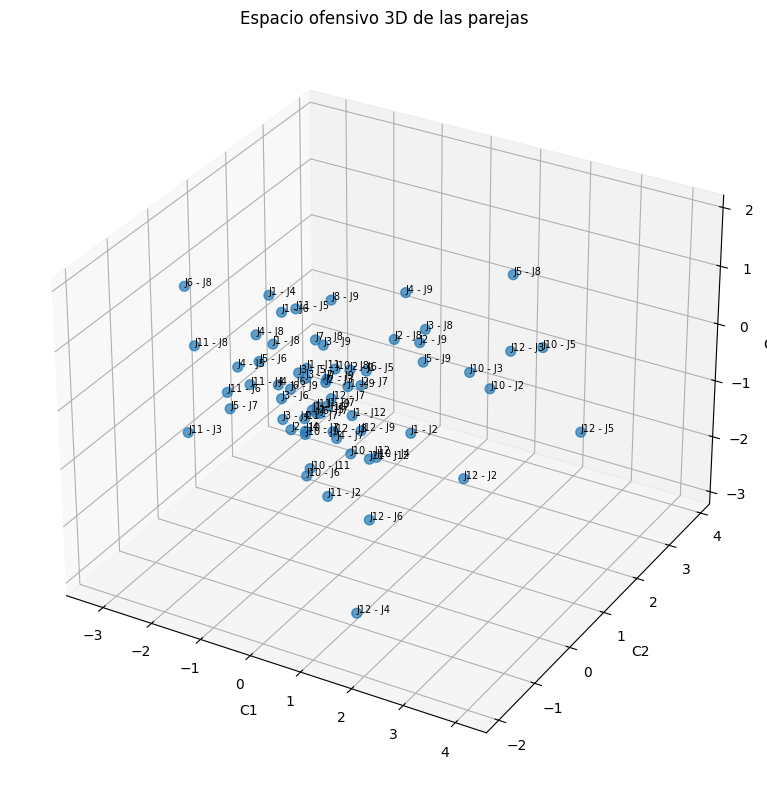

In [46]:
import matplotlib.pyplot as plt

#Creo la figura 3D
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")

# Represento las parejas
ax.scatter(
    X_pca_3d[:, 0],
    X_pca_3d[:, 1],
    X_pca_3d[:, 2],
    s=50,
    alpha=0.7
)

#anado el nombre de cada pareja
for i, pareja in enumerate(df_global["Pareja"]):
    ax.text(
        X_pca_3d[i, 0],
        X_pca_3d[i, 1],
        X_pca_3d[i, 2],
        pareja,
        fontsize=7
    )

#ejes
ax.set_xlabel("C1")
ax.set_ylabel("C2")
ax.set_zlabel("C3")

ax.set_title("Espacio ofensivo 3D de las parejas")

plt.tight_layout()
plt.show()

hay una zona central muy poblada , muchas parejas tienen comportamientos ofensivos relativamente similares.

otras parejas se separan -> perfiles ofensivos más diferenciados

**DISTANCIAS ENTRE PARTICULAS**

Tengo que hacer la matriz de distancia entre las parejas


una distancia pequeña -> indicará perfiles ofensivos similares
viceversa para distancia grande

**es como calcular r_ij= sqrt[( x_i1 - xj_1 )^2 + ( x_i2 - xj_2 )^2 + ( x_i3 - xj_3 )^2 + ( x_i4 - xj_4 )^2 ]**

rij -> la distancia que podré introducir en el potencial inspirado en el de lennard -jones

In [47]:
from sklearn.metrics import pairwise_distances
import pandas as pd

# Distancias entre todas las parejas en el espacio 4D normalizado
matriz_distancias = pairwise_distances(
    X_fisica_norm,
    metric="euclidean"
)

# paso la matriz en DataFrame
distancias_df = pd.DataFrame(
    matriz_distancias,
    index=df_global["Pareja"],
    columns=df_global["Pareja"]
)

print("Dimensiones de la matriz:", distancias_df.shape)

display(distancias_df.round(2))

Dimensiones de la matriz: (65, 65)


Pareja,J1 - J10,J1 - J11,J1 - J12,J1 - J2,J1 - J4,J1 - J5,J1 - J6,J1 - J7,J1 - J8,J1 - J9,...,J5 - J6,J5 - J7,J5 - J8,J5 - J9,J6 - J7,J6 - J8,J6 - J9,J7 - J8,J7 - J9,J8 - J9
Pareja,,,,,,,,,,,,,,,,,,,,,
J1 - J10,0.00,1.32,1.41,1.87,2.13,1.84,1.97,0.90,1.72,1.15,...,1.29,1.69,4.53,2.32,0.81,3.07,0.99,1.86,1.26,2.63
J1 - J11,1.32,0.00,2.09,2.86,1.34,2.25,2.16,0.96,0.73,0.82,...,1.46,1.97,3.85,2.05,0.81,2.95,0.76,1.25,0.38,1.39
J1 - J12,1.41,2.09,0.00,1.50,2.75,0.73,1.99,1.21,2.40,1.51,...,2.53,1.97,4.48,1.89,1.65,3.39,1.58,1.75,1.98,3.10
J1 - J2,1.87,2.86,1.50,0.00,3.65,1.80,2.95,2.11,3.37,2.18,...,3.02,3.15,4.47,2.28,2.26,4.45,2.60,2.95,2.62,3.83
J1 - J4,2.13,1.34,2.75,3.65,0.00,2.64,1.66,2.00,0.78,1.95,...,1.54,2.07,4.37,2.84,2.03,1.96,1.51,1.40,1.68,1.54
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
J6 - J8,3.07,2.95,3.39,4.45,1.96,3.25,1.63,3.18,2.35,3.41,...,2.43,2.01,6.15,4.28,3.34,0.00,2.60,2.56,3.28,3.44
J6 - J9,0.99,0.76,1.58,2.60,1.51,1.84,1.74,0.66,0.93,0.97,...,1.41,1.27,4.39,2.21,0.80,2.60,0.00,1.09,0.92,2.03
J7 - J8,1.86,1.25,1.75,2.95,1.40,1.59,1.60,1.26,1.16,1.29,...,2.19,1.83,3.94,1.85,1.63,2.56,1.09,0.00,1.39,1.70


matriz 65x65 cada elemento de rij representa la distancia entre dos parejas en el espacio ofensivo normalizado.

con diagonal cero -> corresponde a la distancia de cada pareja consigo misma

cuanto menor sea rij , mayor es la similitud entre los perfiles ofensivos

tengo que eliminar esa diagonal de ceros, ya que no aporta informacion

me quedo con la mitad de la matriz para no contar 2 veces j1-j2 y luego j2-j1

para calcular las comparaciones distintas entre aprejas : 65(65-1) / 2 = 2080

divido entre dos porque en la matriz aparecen las combinaciones dos veces , resto 1 porque una pareja no se compara consigo misma

Número de distancias: 2080
Distancia mínima: 0.226
Distancia media: 2.549
Distancia mediana: 2.28
Distancia máxima: 7.504


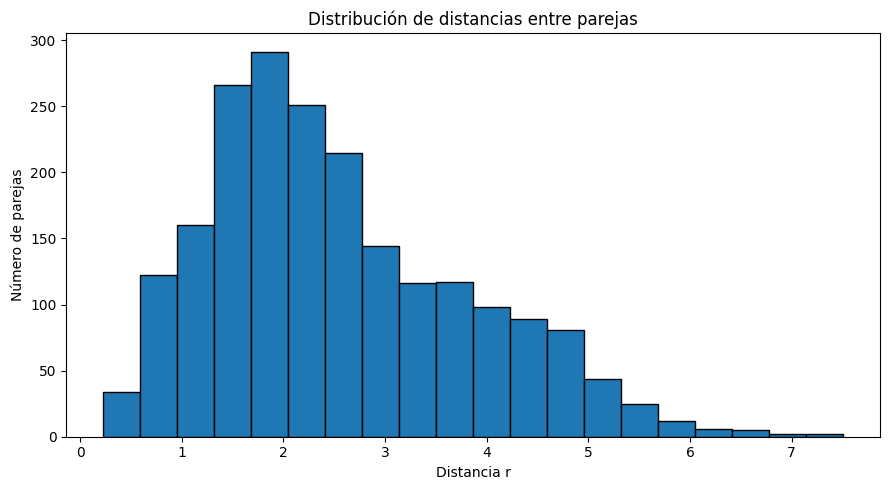

In [48]:
import numpy as np
import matplotlib.pyplot as plt

# me quedo con las distancias unicas
distancias = matriz_distancias[
    np.triu_indices_from(matriz_distancias, k=1)
]

print("Número de distancias:", len(distancias))
print("Distancia mínima:", round(distancias.min(), 3))
print("Distancia media:", round(distancias.mean(), 3))
print("Distancia mediana:", round(np.median(distancias), 3))
print("Distancia máxima:", round(distancias.max(), 3))

#histograma
plt.figure(figsize=(9, 5))
plt.hist(distancias, bins=20, edgecolor="black")

plt.xlabel("Distancia r")
plt.ylabel("Número de parejas")
plt.title("Distribución de distancias entre parejas")

plt.tight_layout()
plt.show()

la mayoria de las distancias entre parejas están entre r=1 y r=3  con una frecuencia máxima de 1,5 - 2 .

a medida de que se aumenta la distancia se disminuye el numero de parejas, aparecen algunos casos muy alejados por las colas  y esos perfiles ofensivos serán más diferenciados.

**POTENCIAL INSPIRADO EN EL DE LENNARD-JONES**

Una vez definida la distancia r entre las parejas, se introduce el potencial inspirado.
en fisica , el modelo de LJ describe como cambia la energia de interaccion entre dos particulas en funcion de la distancia que las separa.

en mi modelo, las particulas son las parejas, r mide la separacion entre los perfiles.

el potencial no representa una interaccion fisica real, sino una analogia para estudiar el sistema .

**V(r) = 4 epsilon [(sigma/r)^12 - (sigma/r)^6]**

r -> distancia entre 2 parejas en el espacio ofensivo

sigma -> escala caracteristica de distancia del sistema

epsilon -> determina la intensidad o la profundidad de la interaccion


La forma de la curva : si r muy pequeña -> V(r) >0

si r intermedia V(r) < 0

si r grande V(r) >0

**¿pero que elijo como sigma y como epsilon?**

para hacerlo de forma fácil supongo que epsilon=1

asi trabajo con un potencial adimensional y me centro en la estructura, no en darle una energia fisica que realmente no exisste.

pero para sigma voy a usar la mediana de las 2080 distancias calculadas

In [49]:
#parametros

epsilon=1

sigma =np.median(distancias)
print("Epsilon:", epsilon)
print("Sigma:", round(sigma,3))

Epsilon: 1
Sigma: 2.28


a 2.28 es la distancia caracteristica entre parejas

por qué la mediana? es una escala basada en mis datos. Y es menos sensible que la media a las parejas que aparecian alejadas por la cola.

DISTANCIA AL MINIMO POTENCIAL

In [50]:
r_min = (2 ** (1/6)) * sigma
print("Sigma:", round(sigma, 3))
print("Distancia de mínimo potencial:", round(r_min, 3))

Sigma: 2.28
Distancia de mínimo potencial: 2.56


el potencial rmin es la distancia de equilibrio (energia potencial tiene su valor minimo)

interpretacion: distancia caracteristica de interaccion entre perfiles ofensivos. Teniendo en cuenta que es una analogia y las parejas no tienen esa energia.

**DIBUJO POTENCIAL LENNARD-JONES INSPIRADO**

curva teorica

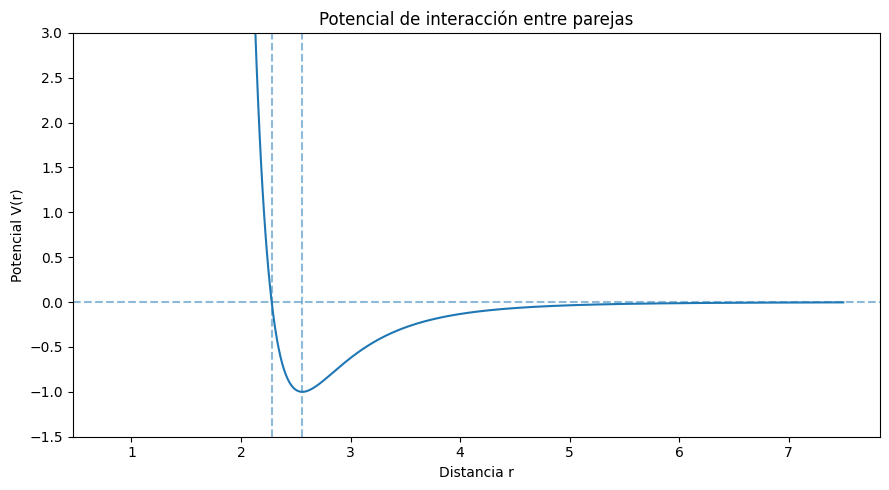

In [51]:
#valores de distancia para representar el potencial
r = np.linspace(0.8, 7.5, 500)

# Potencial de Lennard-Jones
V = 4 * epsilon * (
    (sigma / r)**12 -
    (sigma / r)**6
)

# Graafica
plt.figure(figsize=(9, 5))

plt.plot(r, V)

# Lineas referencia
plt.axhline(0, linestyle="--", alpha=0.5)
plt.axvline(sigma, linestyle="--", alpha=0.5)
plt.axvline(r_min, linestyle="--", alpha=0.5)

plt.xlabel("Distancia r")
plt.ylabel("Potencial V(r)")
plt.title("Potencial de interacción entre parejas")

#limito el eje para poder ver bien el mínimo
plt.ylim(-1.5, 3)

plt.tight_layout()
plt.show()

**LA PUEDO DIVIDIR EN TRES REGIONE**S

**1 r< sigma = 2.28  -> V(r) > 0** . Zona repulsiva dle modelo.

 Las parejas tienen perfiles ofensivos muy próximos entre sí. Analogía -> alta similitud ofensiva


**2 rmin= 2.56 aprox  -> V(r) = -1.** El minimo de pontencial!!

Es la distancia de equilibrio del modelo.

Perfiles que no son practicamente identicos pero mantienen una relacion fuerte en el modelo.


**3 r> 2.56 -> V(r) -> 0 .** Las parejas que se alejan en el espacio ofensivo -> la interaccion disminuye (perfiles cada vez + diferentes) y el potencial tiende a cero.

no estoy diciendo que r=2.56 sea objetivamente la combinacion ofensiva "optima". porque surge matematicamente de haber elegido sigma 2.28 a partir de la mediana y aplicando el LJ .

Luego tengo que comprobar si esta estructura guarda relacion con los perfiles del Kmeans.

**CALCULO V(R) PARA LAS PAREJAS REALES. APLICARLA A LAS 2080 DISTANCIAS REALES**

antes tenia para cada comparacion una distancia rij, ahora tengo que transformar cada una de esas distancias : rij -> V(rij)

In [52]:
V_real = 4 * epsilon * (
    (sigma / distancias)**12 -
    (sigma / distancias)**6
)

print("Número de interacciones:", len(V_real))
print("Potencial mínimo:", round(V_real.min(), 3))
print("Potencial mediano:", round(np.median(V_real), 3))
print("Potencial máximo:", round(V_real.max(), 3))


Número de interacciones: 2080
Potencial mínimo: -1.0
Potencial mediano: 0.0
Potencial máximo: 4436556277056.455


no hay que asustarse con el potencial máximo, es por el termino repulsivo (sigma/r)^12 .

hay al menos 2 parejas con perfiles ofensivos extremadamente próximos -> con un r muy pequeño. Y al dividir 2.28 entre ese numero tan pequeño el potencial se dispara.

OJO!!! esto demuestra muy bien las caracteristicas del potencial Lennard Jones -> que cuando r-> 0 eso implica que V(r)-> a + infinito

INDICA ES QUE HAY PERFILES OFENSIVOS MUY PROXIMOS

QUE PAREJAS SON ESAS? TAN PROXIMAS

primero reconstruyo los indices de las 2080 comparaciones unicas.

con np.argmax(V/real) me va a buscar en qué posicion se encuentra el mayor valor de V(r).

uso la posicion para recuperar PAREJA A <-> PAREJA B

In [53]:
# indices de las parejas de cada una de las 2080 comparaciones
indices_i, indices_j = np.triu_indices_from(
    matriz_distancias,
    k=1
)

# Posición del potencial máx
idx_max = np.argmax(V_real)

# Parejas correspondientes
i = indices_i[idx_max]
j = indices_j[idx_max]

pareja_1 = df_global["Pareja"].iloc[i]
pareja_2 = df_global["Pareja"].iloc[j]

print("Pareja 1:", pareja_1)
print("Pareja 2:", pareja_2)
print("Distancia r:", round(distancias[idx_max], 4))
print("Potencial V(r):", V_real[idx_max])

Pareja 1: J2 - J3
Pareja 2: J7 - J9
Distancia r: 0.2261
Potencial V(r): 4436556277056.455


estas dos parejas presentan la menor separacion relevante del sistema r=0.2261 , implica perfiles ofensivos muy similares.

Al aplicar el potencial LJ, esta proximidad genera un valor positivo muy elevado con el termino elevado 12.

Analogia: esta region puede interpretarse como una elevada redundancia entre perfiles ofensivos.

**PAREJAS PROXIMAS AL EQUILIBRIO**

rmin 2.56 y V(rmin)=-1

quiero las parejas cuya separacion se encuentre en la zona de minimo potencial definida por mi modelo .

No son perfiles practicamente identicos pero su separacion coincide con la escala de equilibrio que se ha construido

In [54]:
idx_equilibrio = np.argmin(
    np.abs(distancias - r_min)
)

# Recupero los índices de las dos parejas
i_eq = indices_i[idx_equilibrio]
j_eq = indices_j[idx_equilibrio]

pareja_1_eq = df_global["Pareja"].iloc[i_eq]
pareja_2_eq = df_global["Pareja"].iloc[j_eq]

print("Pareja 1:", pareja_1_eq)
print("Pareja 2:", pareja_2_eq)
print("Distancia r:", round(distancias[idx_equilibrio], 4))
print("Potencial V(r):", round(V_real[idx_equilibrio], 4))

Pareja 1: J11 - J3
Pareja 2: J12 - J8
Distancia r: 2.5595
Potencial V(r): -1.0


he encontrado una interacion real situada practicamente en el minimo de potencial!!!

Las parejas j11-j3 y la j12-j8  presentan la distancia r de 2.5595 que practicamente coincide con la distancia del minimo rmin 2.56 -> que se alcanza V(r)=-1  -> las parejas se situan en la region de equilibrio definida por el potencial

OJO!!! esto no quiere decir que sean las mejores parejas y tampoco que deban de jugar juntas . estamos comparando los perfiles ofensivos y viendo que su separacion coincide con el minimo del modelo

**CLASIFICO LAS INTERACCIONES SEGUN LA REGION DEL POTENCIAL**

r< sigma -> region repulsiva

sigma < = r < = 2 rmin -> region atractiva

r > 2 rmin -> interaccion debil

In [55]:
repulsivas = np.sum(distancias < sigma)

atractivas = np.sum(
    (distancias >= sigma) &
    (distancias <= 2 * r_min)
)

debiles = np.sum(distancias > 2 * r_min)

print("Interacciones repulsivas:", repulsivas)
print("Interacciones atractivas:", atractivas)
print("Interacciones débiles:", debiles)

print("Total:", repulsivas + atractivas + debiles)


Interacciones repulsivas: 1040
Interacciones atractivas: 961
Interacciones débiles: 79
Total: 2080


de todas las interaciones que son 2080 , 1040 se encuentran en la zona repulsiva.
OJO! la mitad!!  eso es debido de haber definido sigma mediante la mediana de las distancias.

Ademas, gran parte de las distancias restantes se encuentran dentro de la región atractiva del modelo.

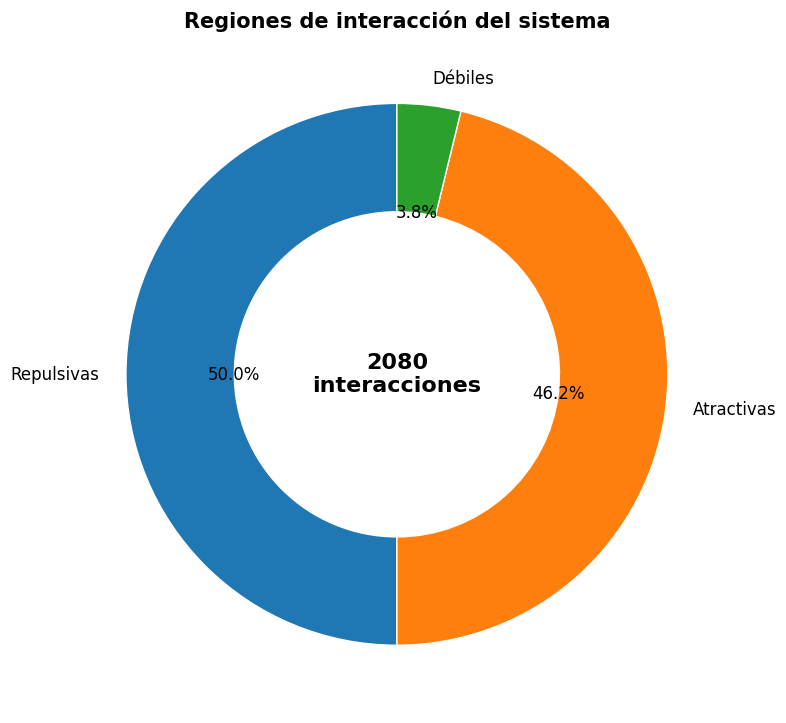

In [56]:
# Datos
categorias = ["Repulsivas", "Atractivas", "Débiles"]
valores = [repulsivas, atractivas, debiles]

plt.figure(figsize=(8, 8))

plt.pie(
    valores,
    labels=categorias,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.40, "edgecolor": "white"},
    textprops={"fontsize": 12}
)

# Num total en el centro
plt.text(
    0, 0,
    "2080\ninteracciones",
    ha="center",
    va="center",
    fontsize=16,
    fontweight="bold"
)

plt.title(
    "Regiones de interacción del sistema",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

**FISICA VS machine learning**

me pregunto si las parejas que el kmeans agrupó por tener comportamientos ofensivos similares tb presentan distancias e interacciones caracteristicas en el modelo fisico.

recuerdo que con el df_global ya tengo el perfil asignado de kmeans en la columna de perfil

**COMPARO DISTANCIAS DENTRO Y FUERA DE LOS CLUSTERS**

Como hipotesis **r mismo perfil < rperfiles diferentes**

las particulas agrupadas por kmeans dentro de un mismo perfil esten tambien más proximas en el espacio fisico.

**si esto pasa :  kmeans agrupa perfiles similares <-> el modelo fisico lo situa a menor distancia.**

In [57]:
# Perfiles obtenidos previiamente con Kmeans
perfiles = df_global["Perfil"].values

dist_mismo_perfil = []
dist_distinto_perfil = []

# Recorro las 2080 comparaciones úniccas
for k in range(len(distancias)):

    i = indices_i[k]
    j = indices_j[k]

    if perfiles[i] == perfiles[j]:
        dist_mismo_perfil.append(distancias[k])
    else:
        dist_distinto_perfil.append(distancias[k])

# Convierto a arrays
dist_mismo_perfil = np.array(dist_mismo_perfil)
dist_distinto_perfil = np.array(dist_distinto_perfil)

print("Comparaciones dentro del mismo perfil:",
      len(dist_mismo_perfil))

print("Comparaciones entre perfiles diferentes:",
      len(dist_distinto_perfil))

print("\nDistancia media - mismo perfil:",
      round(dist_mismo_perfil.mean(), 3))

print("Distancia media - perfiles diferentes:",
      round(dist_distinto_perfil.mean(), 3))

Comparaciones dentro del mismo perfil: 490
Comparaciones entre perfiles diferentes: 1590

Distancia media - mismo perfil: 1.422
Distancia media - perfiles diferentes: 2.896


entonces al ser rmin < rperfiles diferentes  aparece la conexion entre kmeans y la representacion fisica.

ojo! las parejas que estan en el mismo perfil de kmeans estan , en promedio, mucho más proximas en el espacio ofensivo


ademas si divido 2.896/1.422 = 2.04  -> las parejas de perfiles diferentes están aproximadamente 2 veces más alejadas que los del mismo perfil .

**Esto es una comprobacion de coherencia** -> no una validacion completamente independiente del kmeans xk tanto los clustering como las muestras de las distancias proceden de las 4 variables ofensivas normalizadas.

**GRAFICA ULTIMA, DISTANCIA SEGUN KMEANS**

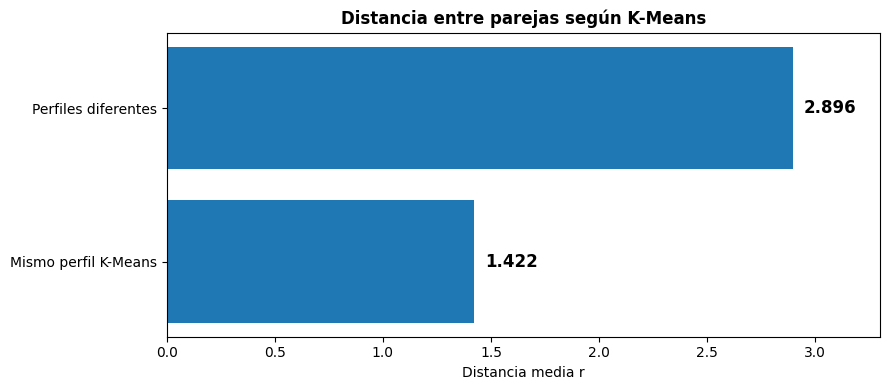

In [58]:
# Distancia medias
categorias = ["Mismo perfil K-Means", "Perfiles diferentes"]
valores = [
    dist_mismo_perfil.mean(),
    dist_distinto_perfil.mean()
]

plt.figure(figsize=(9, 4))

barras = plt.barh(categorias, valores)

# Muestro el valor al fiinal de cada barra
for barra, valor in zip(barras, valores):
    plt.text(
        valor + 0.05,
        barra.get_y() + barra.get_height()/2,
        f"{valor:.3f}",
        va="center",
        fontsize=12,
        fontweight="bold"
    )

plt.xlabel("Distancia media r")
plt.title(
    "Distancia entre parejas según K-Means",
    fontweight="bold"
)

plt.xlim(0, 3.3)
plt.tight_layout()
plt.show()

las parejas que pertenecen al mismo perfil de kmeans presentan una distancia media MENOR  que las que son de los perfiles diferentes

MUESTRA CORRESPONDENCIA  entre el clustering y la proximidad en el espacio ofensivo.

**ahora bien, las interacciones entre parejas del mismo perfil de kmeans se comportan de forma DIFERENTE a las interacciones entre perfiles diferentes dentro del potencial???**.

necesito saber -> cómo se distribuyen las interacciones fisicas dependiendo de si kmeans puso las parejas en el mismo perfil o en perfiles diferentes

In [59]:
# Guardo la region de cada interacción
regiones = []

for r in distancias:
    if r < sigma:
        regiones.append("Repulsiva")
    elif r <= 2 * r_min:
        regiones.append("Atractiva")
    else:
        regiones.append("Débil")

# Separo segun Kmeans
regiones_mismo = []
regiones_distinto = []

for k in range(len(distancias)):

    i = indices_i[k]
    j = indices_j[k]

    if perfiles[i] == perfiles[j]:
        regiones_mismo.append(regiones[k])
    else:
        regiones_distinto.append(regiones[k])

# conteo cada region
for nombre, grupo in [
    ("MISMO PERFIL", regiones_mismo),
    ("PERFILES DIFERENTES", regiones_distinto)
]:
    print("\n", nombre)

    for region in ["Repulsiva", "Atractiva", "Débil"]:
        cantidad = grupo.count(region)
        porcentaje = cantidad / len(grupo) * 100

        print(
            region,
            ":",
            cantidad,
            f"({porcentaje:.1f}%)"
        )


 MISMO PERFIL
Repulsiva : 438 (89.4%)
Atractiva : 52 (10.6%)
Débil : 0 (0.0%)

 PERFILES DIFERENTES
Repulsiva : 602 (37.9%)
Atractiva : 909 (57.2%)
Débil : 79 (5.0%)


se ve la conexion

importante!! el 89.4%  cuando los kmeans coloca dos parejas dentro del mismo perfil , casi 9 de cada 10 comparaciones están en la region de las distancias MENORES que sigma.

entre perfiles diferentes predomina la region atractiva y aparecen todas como debiles.

hay correspondencia mediante el kmeans con la estructura geometrica y energetica dle modelo.

ojo !! repulsiva no es que sean malas parejas en baloncesto , solo es la región definida r menor sigma , que me está señalando la gran proximidad del perfil

**conclusion:** kmeans agrupó como un mismo perfil a las parejas con caracteristicas ofensivas similares

El modelo fisico -> confirma que esas parejas se encuentran a distancias pequeñas entre si.

2 métodos distintos de representacion de datos me dan la misma estructura.
Los perfiles que se agrupan en kmeans son tambien los que aparecen más proximos en el espacio fisico.

**GRAFICA COMPARACION DE LAS REGIONES SEGUN KMEANS**

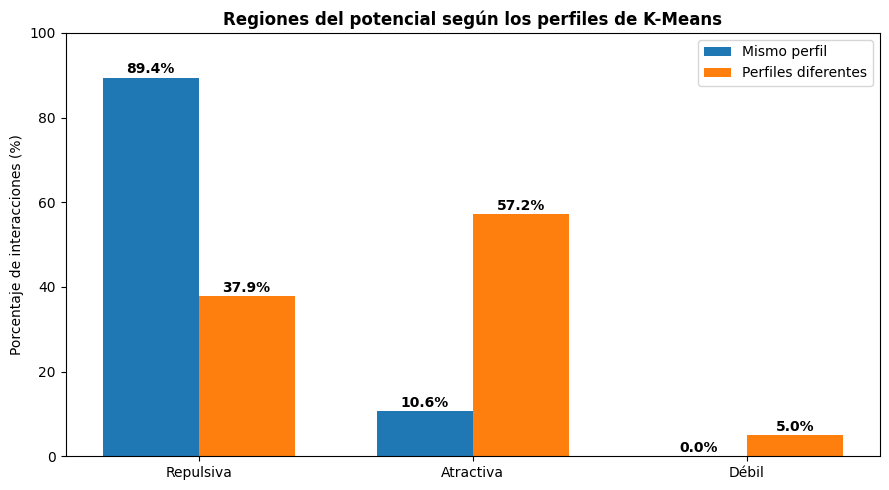

In [60]:
# datos en porcentaje
regiones = ["Repulsiva", "Atractiva", "Débil"]

mismo_perfil_pct = [89.4, 10.6, 0.0]
diferente_perfil_pct = [37.9, 57.2, 5.0]

x = np.arange(len(regiones))
ancho = 0.35

plt.figure(figsize=(9, 5))

b1 = plt.bar(
    x - ancho/2,
    mismo_perfil_pct,
    ancho,
    label="Mismo perfil"
)

b2 = plt.bar(
    x + ancho/2,
    diferente_perfil_pct,
    ancho,
    label="Perfiles diferentes"
)

# valores sobre las barras
for barras in [b1, b2]:
    for barra in barras:
        altura = barra.get_height()
        plt.text(
            barra.get_x() + barra.get_width()/2,
            altura + 1,
            f"{altura:.1f}%",
            ha="center",
            fontsize=10,
            fontweight="bold"
        )

plt.xticks(x, regiones)
plt.ylabel("Porcentaje de interacciones (%)")
plt.title(
    "Regiones del potencial según los perfiles de K-Means",
    fontweight="bold"
)

plt.ylim(0, 100)
plt.legend()

plt.tight_layout()
plt.show()

aqui veo donde caen las parejas en el potencial fisico segun kmeans

region repulsiva -> el 89,4% de las comparaciones del mismo perfil estan aqui frente al 37,9 %  -> r menor que sigma  . kmeans está agrupando las parejas que estan muy proximas en el espacio ofensivo

en la region atractiva : solo el 10.6% de las comparaciones del mismo perfil están aqui mientras que el perfil de diferentes está a 57,2%  . **LOgica!! al pertenecer a perfiles diferentes , sus caracteristicas ofensivas tienden a estar más separadas.**

la region debil -> no aparece ninguna del mismo perfil 0% y hay un 5% de perfiles diferentes. **LOgica!!!! Las parejas muy alejadas entre si nunca fueron agrupadas por kmeans dentro del mismo perfil**

**MISMO CLUSTER -> MENOR DISTANCIA**

**CLUSTER DIFERENTE -> MAYOR DISTANCIA**

KMEANS identifica grupos de perfiles ofensivos similares y cuando estos datos se interpretan como particulas tambien aparecen geometricamente proximos.

**IMPORTANTE!!!!!!** Esta correspondencia es esperable, ya que tanto kmeans como el cálculo de distancias parten de las mismas variables ofensivas.

**Este resultado se interpreta como una COMPROBACIÓN de la COHERENCIA GEOMETRICA del modelo y NO como una VALIDACION INDEPENDIENTE DE KMEANS**

TERCERA PARTE!!!!!!! VALIDACIÓN!!!!!!

Hasta aquí he estudiado la estructura y similut de las parejas en el espacio ofensivo.

**Objetivo nuevo:**  comprobar si esta estructura presenta alguna relación con el rendimiento real en pista.

-Tengo que añadir los csv de los quintetos reales y veré si la similitud o diversidad de las parejas que forman cada quinteto está relacionada con su rendimiento.

PRIMERO : CARGAR LOS CSV DE LOS QUINTETOS QUE YA TENGO

In [61]:
import pandas as pd
import glob
import os

Con glob.glob  busca todos los archivos .csv

In [62]:
ruta_quintetos = "/content/drive/MyDrive/TFG_UGR/Proyecto_Parejas/csv_quintetos"

# Buscar todos los CSV
archivos_quintetos = glob.glob(os.path.join(ruta_quintetos, "*.csv"))

print("Número de archivos encontrados:", len(archivos_quintetos))

for archivo in archivos_quintetos:
    print(os.path.basename(archivo))

Número de archivos encontrados: 7
quintetos_Espana_C.csv
quintetos_Espana_S.csv
quintetos_Espana_E.csv
quintetos_Espana_I.csv
quintetos_Espana_M.csv
quintetos_Espana_F.csv
quintetos_Espana_T.csv


quiero saber que hay en cada columna

pd.read()  carga uno de los partidos y con .columns.tolist me enseña todas las variables que hay

In [63]:
# Leo el primer CSVquintetos
df_q_test = pd.read_csv(archivos_quintetos[0])

print("Dimensiones:", df_q_test.shape)
print("\nColumnas:")
print(df_q_test.columns.tolist())

display(df_q_test.head())

Dimensiones: (21, 10)

Columnas:
['Quarter', 'Time', 'Quinteto', 'Tiempo_seg', 'Fin_seg', 'Duracion_seg', 'Minutos', 'PF', 'PC', '+/-']


,Quarter,Time,Quinteto,Tiempo_seg,Fin_seg,Duracion_seg,Minutos,PF,PC,+/-
0,Q1,10:00,"['P_370376', 'P_370814', 'P_370816', 'P_417675...",600,310.0,290.0,4.833333,15,3,12
1,Q1,5:10,"['P_285267', 'P_345123', 'P_346898', 'P_371704...",310,256.0,54.0,0.900000,2,4,-2
2,Q1,4:16,"['P_285267', 'P_346898', 'P_370814', 'P_371704...",256,202.0,54.0,0.900000,2,0,2
3,Q1,3:22,"['P_346898', 'P_370376', 'P_370814', 'P_417675...",202,109.0,93.0,1.550000,6,0,6
4,Q1,1:49,"['P_285267', 'P_370376', 'P_370814', 'P_417675...",109,0.0,109.0,1.816667,2,0,2


ahora me toca unir los 7 partidos en un unico dataframe

pero yo quiero consevar Partido, porque en un mismo quinteto puede aparecer en distintos encuentros y no quiero mezclar sus rendimientos

In [64]:
# Unir los CSV de quintetos d tods los partidos

lista_quintetos = []

for archivo in archivos_quintetos:

    df_temp = pd.read_csv(archivo)

    # Guardo de q partido procede cada fila
    df_temp["Partido"] = os.path.basename(archivo).replace(".csv", "")

    lista_quintetos.append(df_temp)

# Unirtodos los partidos
df_quintetos = pd.concat(lista_quintetos, ignore_index=True)

print("Número total de intervalos de quintetos:", len(df_quintetos))
print("Número de partidos:", df_quintetos["Partido"].nunique())

display(df_quintetos.head())

Número total de intervalos de quintetos: 174
Número de partidos: 7


,Quarter,Time,Quinteto,Tiempo_seg,Fin_seg,Duracion_seg,Minutos,PF,PC,+/-,Partido
0,Q1,10:00,"['P_370376', 'P_370814', 'P_370816', 'P_417675...",600,310.0,290.0,4.833333,15,3,12,quintetos_Espana_C
1,Q1,5:10,"['P_285267', 'P_345123', 'P_346898', 'P_371704...",310,256.0,54.0,0.900000,2,4,-2,quintetos_Espana_C
2,Q1,4:16,"['P_285267', 'P_346898', 'P_370814', 'P_371704...",256,202.0,54.0,0.900000,2,0,2,quintetos_Espana_C
3,Q1,3:22,"['P_346898', 'P_370376', 'P_370814', 'P_417675...",202,109.0,93.0,1.550000,6,0,6,quintetos_Espana_C
4,Q1,1:49,"['P_285267', 'P_370376', 'P_370814', 'P_417675...",109,0.0,109.0,1.816667,2,0,2,quintetos_Espana_C


ahora me toca convertir cada quinteto de 5 jugadoras en sus 10 parejas posibles

pero antes tengo que resolver una cosa! los codigos de los jugadores los tengo que sustituir por j1, j2, etc

In [65]:
jugadoras = {
    "P_417675": "J1",
    "P_285267": "J2",
    "P_371704": "J3",
    "P_345123": "J4",
    "P_305487": "J5",
    "P_346898": "J6",
    "P_417830": "J7",
    "P_370792": "J8",
    "P_370814": "J9",
    "P_370816": "J10",
    "P_370376": "J11",
    "P_395401": "J12"
}

In [66]:
import ast

# Convertir el quinteto guardado como texto en una lista
df_quintetos["Quinteto_lista"] = df_quintetos["Quinteto"].apply(ast.literal_eval)

# Cambiar códigos P_... por J1, J2...
df_quintetos["Quinteto_J"] = df_quintetos["Quinteto_lista"].apply(
    lambda q: [jugadoras.get(j, j) for j in q]
)

display(
    df_quintetos[
        ["Quinteto", "Quinteto_J", "Minutos", "PF", "PC", "+/-"]
    ].head()
)

,Quinteto,Quinteto_J,Minutos,PF,PC,+/-
0,"['P_370376', 'P_370814', 'P_370816', 'P_417675...","[J11, J9, J10, J1, J7]",4.833333,15,3,12
1,"['P_285267', 'P_345123', 'P_346898', 'P_371704...","[J2, J4, J6, J3, J7]",0.900000,2,4,-2
2,"['P_285267', 'P_346898', 'P_370814', 'P_371704...","[J2, J6, J9, J3, J7]",0.900000,2,0,2
3,"['P_346898', 'P_370376', 'P_370814', 'P_417675...","[J6, J11, J9, J1, J7]",1.550000,6,0,6
4,"['P_285267', 'P_370376', 'P_370814', 'P_417675...","[J2, J11, J9, J1, J7]",1.816667,2,0,2


Ahora tengo que generar las 10 parejas que contienen cada quinteto y las conservo en una nueva columna

que hace combinations(q,2)?

cojo las 5 jugadoras de ese quinteto de dos en dos , SIN REPETIR combinaciones

si tuviese j1, j2,j3,j4 y j5 tendria j1-j2 , j1-j3, j1-j4 .... hasta hacere las 10 parejas

uso sorted xk me deja los identificadores siempre en el mismo orden

In [67]:
import ast

# Convertir el quinteto guardado como txt en una lista
df_quintetos["Quinteto_lista"] = df_quintetos["Quinteto"].apply(ast.literal_eval)

# Cambiar códigos P_... por J1, J2...
df_quintetos["Quinteto_J"] = df_quintetos["Quinteto_lista"].apply(
    lambda q: [jugadoras.get(j, j) for j in q]
)

display(
    df_quintetos[
        ["Quinteto", "Quinteto_J", "Minutos", "PF", "PC", "+/-"]
    ].head()
)

,Quinteto,Quinteto_J,Minutos,PF,PC,+/-
0,"['P_370376', 'P_370814', 'P_370816', 'P_417675...","[J11, J9, J10, J1, J7]",4.833333,15,3,12
1,"['P_285267', 'P_345123', 'P_346898', 'P_371704...","[J2, J4, J6, J3, J7]",0.900000,2,4,-2
2,"['P_285267', 'P_346898', 'P_370814', 'P_371704...","[J2, J6, J9, J3, J7]",0.900000,2,0,2
3,"['P_346898', 'P_370376', 'P_370814', 'P_417675...","[J6, J11, J9, J1, J7]",1.550000,6,0,6
4,"['P_285267', 'P_370376', 'P_370814', 'P_417675...","[J2, J11, J9, J1, J7]",1.816667,2,0,2


hago la funcion combinations (q,2)

In [68]:
from itertools import combinations

# Crear las 10 parejas posibles d cada quinteto
df_quintetos["Parejas"] = df_quintetos["Quinteto_J"].apply(
    lambda q: ["-".join(sorted(p, key=lambda x: int(x[1:])))
               for p in combinations(q, 2)]
)

# Comprobar el primer quintet
print("Quinteto:")
print(df_quintetos["Quinteto_J"].iloc[0])

print("\nSus 10 parejas:")
print(df_quintetos["Parejas"].iloc[0])

print("\nNúmero de parejas:", len(df_quintetos["Parejas"].iloc[0]))

Quinteto:
['J11', 'J9', 'J10', 'J1', 'J7']

Sus 10 parejas:
['J9-J11', 'J10-J11', 'J1-J11', 'J7-J11', 'J9-J10', 'J1-J9', 'J7-J9', 'J1-J10', 'J7-J10', 'J1-J7']

Número de parejas: 10


tengo: quinteto -> sus 10 parejas -> caracteristicas /distancias -> rendimiento del quinteto (+- , pf, pc)..

**VALIDAR SI LA ESTRUCTURA DE LAS PAREJAS QUE FORMAN UN QUINTETO TIENE RELACION CON SU RENDIMIENTO EN PISTA**

Tengo qu conectar las 10 parejas con el df_global donde ya tengo las caracteristicas

la funcion normalizar-pareja pone siempre primero a la jugadora con numero menor. ejemplo j8-j1 lo pondria como j1-j8 , esto es para evitar considerar distintas dos parejas que realmente son la misma


true es para que la pareja del quinteto si existe en el dataset

In [69]:
# FUNCIÓN PARA PONER LAS PAREJAS SIEMPRE EN EL MISMO ORDEN
def normalizar_pareja(pareja):
    j1, j2 = pareja.split("-")

    # Ordeno x número d jugadora
    jugadores = sorted(
        [j1, j2],
        key=lambda x: int(x.replace("J", ""))
    )

    return f"{jugadores[0]}-{jugadores[1]}"

he escrito mal los j1-j2 es que hay espacios j1 - j2

In [70]:
# NORMALIZAR EL NOMBRE DE LAS PAREJAS
def normalizar_pareja(pareja):

    # Quito espacios
    pareja = pareja.replace(" ", "")

    j1, j2 = pareja.split("-")

    # Ordenar x num de jugadora
    jugadores = sorted(
        [j1, j2],
        key=lambda x: int(x.replace("J", ""))
    )

    return f"{jugadores[0]}-{jugadores[1]}"


# Volver a normalizar df_global
df_global["Pareja_norm"] = df_global["Pareja"].apply(normalizar_pareja)


# Repetir la comprobacioon
parejas_prueba = df_quintetos["Parejas"].iloc[0]

for pareja in parejas_prueba:
    pareja_norm = normalizar_pareja(pareja)
    existe = pareja_norm in df_global["Pareja_norm"].values

    print(pareja, "→", pareja_norm, "→", existe)


J9-J11 → J9-J11 → True
J10-J11 → J10-J11 → True
J1-J11 → J1-J11 → True
J7-J11 → J7-J11 → True
J9-J10 → J9-J10 → True
J1-J9 → J1-J9 → True
J7-J9 → J7-J9 → True
J1-J10 → J1-J10 → True
J7-J10 → J7-J10 → True
J1-J7 → J1-J7 → True


que salga todo true es IMPORTANTEEEEEEE

ya que puedo empezar la validacionn nueva : para cada intervalo de quinteto puedo recuperar la informacion de sus 10 parejas -> construir una medida de cómo de similares/diferentes  son entre si -> luego las relacione con el +- , el pf, el pc reales del quineto

ahora tengo que recorrer todos los intervalos de quinteto y comprobar sus 10 parejas contra df_global

In [71]:
# COMPROBAR TODAS LAS PAREJAS de TODS LOS QUINTETOS
parejas_disponibles = set(df_global["Pareja_norm"])

total = 0
encontradas = 0
no_encontradas = set()

for lista_parejas in df_quintetos["Parejas"]:

    for pareja in lista_parejas:
        total += 1

        pareja_norm = normalizar_pareja(pareja)

        if pareja_norm in parejas_disponibles:
            encontradas += 1
        else:
            no_encontradas.add(pareja_norm)

print("Comparaciones totales:", total)
print("Parejas encontradas:", encontradas)
print("Parejas diferentes no encontradas:", len(no_encontradas))

if no_encontradas:
    print("\nParejas que faltan:")
    print(sorted(no_encontradas))
else:
    print("\n¡Todas las parejas estan disponibles!")

Comparaciones totales: 1740
Parejas encontradas: 1740
Parejas diferentes no encontradas: 0

¡Todas las parejas estan disponibles!


puedo relacionar cada intervalo de quinteto con las 10 parejas que lo forman sin perder ningún caso

**CONSTRUIR LA VARIABLE DE VALIDACIÓN**

-para cada quinteto tengo que calcular cómo de proximas/alejadas estan sus parejas en el espacio ofensivo

**los quintetos formados x parejas muy similares tienen un +- diferente de aquellos cuya parejas son + diversas?**

**MEDIDA DE DESTANCIA PARA CADA QUINTETO**

a ver , si cada quinteto tiene 10 parejas yo quiero saber como de separadas están esas 10 parejas entre si en el espacio ofensivo construido con las 4 variables..

tengo que calcular para cada quinteto las distancias entre esas 10 parejas y luego calcular su distancia media

In [72]:
from scipy.spatial.distance import pdist
import numpy as np

# Variables del espacio ofensivoo
variables_fisica = [
    "Aro/min",
    "Media/min",
    "Triple/min",
    "PB/min"
]

qué calculo ?  si por ejemplo me sale un quinteto j1-j3-j7-j8-j10 y genera sus 10 paejas -> esas 10 parejas son 10 puntos del espacio ofensivo 4D


pdist() me va a calcular las distancias entre todos esos puntos

si son 10 puntos la combinacion (10 2) =45  distancias

mean -> se obtiene una sola cifra para resumir el quinteto

**la distancia media pequeña ->** las parejas q forman ese quineto tienen perfiles ofensivos bastante similares

**distancia media grande ->** dentro del quinteto conviven parejas con perfiles ofensivos más diferentes

**DISTANCIA VS RENDIMIENTO**

In [73]:
# diccionario
# Pareja normalizada -> cordenadas normalizadas del espacio ofensivo
coords_parejas = {
    df_global["Pareja_norm"].iloc[i]: X_fisica_norm[i]
    for i in range(len(df_global))
}


def distancia_media_quinteto(lista_parejas):

    # Buscar ls coordenadas de las 10 parejas
    coordenadas = [
        coords_parejas[normalizar_pareja(p)]
        for p in lista_parejas
    ]

    coordenadas = np.array(coordenadas)

    # Distancias entre las 10 parejas
    distancias = pdist(coordenadas, metric="euclidean")

     # Distancia media
    return distancias.mean()

In [74]:
# Calculamr la distancia media para cad intervalo de quinteto
df_quintetos["Distancia_media"] = (
    df_quintetos["Parejas"].apply(distancia_media_quinteto)
)

display(
    df_quintetos[
        ["Quinteto_J", "Minutos", "PF", "PC", "+/-", "Distancia_media"]
    ].head(10)
)


,Quinteto_J,Minutos,PF,PC,+/-,Distancia_media
0,"[J11, J9, J10, J1, J7]",4.833333,15,3,12,1.245619
1,"[J2, J4, J6, J3, J7]",0.900000,2,4,-2,1.073810
2,"[J2, J6, J9, J3, J7]",0.900000,2,0,2,1.221062
3,"[J6, J11, J9, J1, J7]",1.550000,6,0,6,1.324651
4,"[J2, J11, J9, J1, J7]",1.816667,2,0,2,1.584706
5,"[J2, J11, J9, J1, J7]",0.833333,0,0,0,1.584706
6,"[J2, J5, J6, J9, J1]",1.716667,5,0,5,1.989987
7,"[J2, J5, J4, J6, J3]",3.366667,7,1,6,1.142926
8,"[J4, J6, J10, J3, J7]",2.816667,12,2,10,1.786406
9,"[J11, J9, J10, J1, J7]",1.266667,2,1,1,1.245619


no se parece ver que "menor distancia = mejor rendimiento" de forma automatica

esto puede ser positivo ya que no estoy intentando demostrar una idea sino una hipotesis para constractar

en la fila 5 y 6 aparece el mismo quinteto!!! y tiene la misma distancia pero distinto +-

esto confirma que la distancia describe la composicion /caracteristicas del quinteto -> mientras que el rendimiento depende de lo que ocurre durante cada intervalo

**VALIDAR DISTANCIA <-> RENDIMIENTO**

tengo que calcular la distancia media y el +-  para poder dibujar la dispersion con linea de tendencia

quiero mirar !!! la correlacion estará entre -1 y + 1

**si cerca de + 1 ->** a mayor distancia, mayor +-

**si cerca de -1 ->** a mayor distancia , menor +-

**si cerca de 0 ->** no observo una relacion lineal claroa

Correlación Distancia media - +/-: -0.0


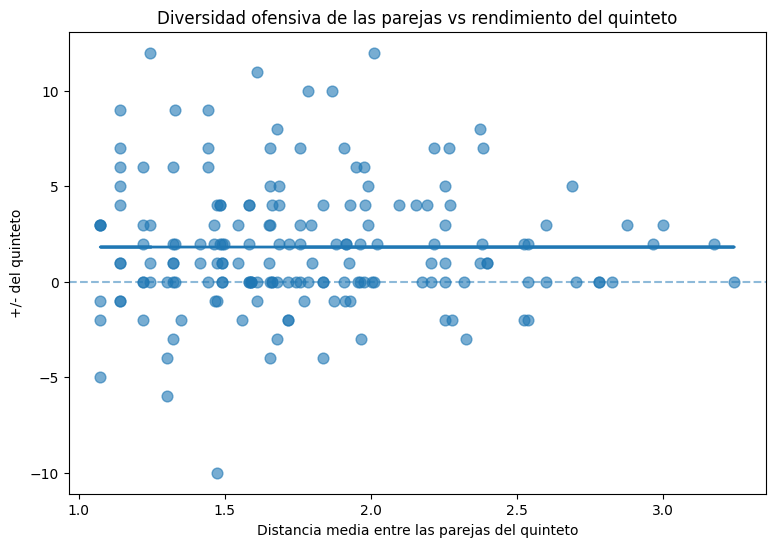

In [75]:
import numpy as np
import matplotlib.pyplot as plt

# Correlacion entre distancia media y +/-
correlacion = df_quintetos["Distancia_media"].corr(df_quintetos["+/-"])

print("Correlación Distancia media - +/-:", round(correlacion, 3))


# grafica
x = df_quintetos["Distancia_media"]
y = df_quintetos["+/-"]

plt.figure(figsize=(9, 6))

plt.scatter(x, y, s=60, alpha=0.6)

#linea de tendencia
m, b = np.polyfit(x, y, 1)
plt.plot(x, m*x + b, linewidth=2)

plt.axhline(0, linestyle="--", alpha=0.5)

plt.xlabel("Distancia media entre las parejas del quinteto")
plt.ylabel("+/- del quinteto")
plt.title("Diversidad ofensiva de las parejas vs rendimiento del quinteto")

plt.show()

cada punto azul es un intervalo de quinteto

**EJE X** tengo la distancia media entre las parejas del quinteto:

 cuanto más a la izquierda + parecidas son ofensivamente sus parejas

cuanto mas a la derecha, mas diferentes son .

**EJE Y:**  tengo el +-

por encima de 0 es que en ese intervalo España anotó mas punto que recibió,

 por debajo de 0 -> recibió mas

**si miro la nube de puntos** -> tanto las distancias pequeñas como las grandes aparecen en valores positivos, negativos y cerca del 0

la linea de tendencia está casi horizontal aunque baja ligeramente

**EN ESTOS DATOS NO APARECE UNA RELACION CLARA ENTRE LA DISTANCIA MEDIA DE LAS PAREJAS DE UN QUINTETO Y SU +-**

la hipotesis decia que quizá los quintetos con parejas más diferentes tengan mejor rendimiento -> de momento no hay evidencia de ello.

**OJOOOOOOO!!** enl a zona de distancia proxima a 1-2 tengo valores cerca de -10 y hasta +12 -> **una distancia parecida puede corresponder a rendimientos completamente distintos**

SIGUIENTE PASO : CALCULAR LA CORRELACION ENTRE DISTANCIA MEDIA Y EL +-

**calculo la correlacion de pearson** entre la distancia media de las parejas de cada quinteto y su rendimiento +-

**aqui r nos va a deci**r la fuerza y la direccion de la relacion

si es cerca de 0 será practicamente que no haya relacion lineal

si es cereca de 1 la relacion positiva fuerte

si es cerca de -1 sera negativa fuerte



**p me va a aclarar** a comprobar si esa relacion tiene evidencia estadistica suficiente o si podria deberese al azar

In [76]:
from scipy.stats import pearsonr

# Correlación entre distancia media y rendimiento
r, p = pearsonr(
    df_quintetos["Distancia_media"],
    df_quintetos["+/-"]
)

print("Correlación de Pearson:", round(r, 3))
print("p-valor:", round(p, 4))


Correlación de Pearson: -0.0
p-valor: 0.9998


la correlacion es practicamente nula r=0

p tiene un valor de 0,9998

**NO SE OBSERVA UNA RELACION LINEAL SIGNIFICATIVA ENTRE LA DISTANCIA MEDIA DE LAS PAREJAS DE UN QUINTETO Y SU RENDIMIENTO +-**

la relacion puede ser no lineal??? esto tiene sentido ya que el potencial de Lennard-JOnes no describe una relacion lineal

**COMPROBAR SI EXISTE UNA RELACION NO LINEAL**

como pearson solo detecta realaciones lineales, puedo usar Spearman -> este comprueba si al aumentar la distancia el rendimiento tiende a aumentar o disminuir aunque la relacion no sea una recta

In [77]:
from scipy.stats import spearmanr

# Relación no necesariamente lineal entre distancia y rendimient
rho, p_spearman = spearmanr(
    df_quintetos["Distancia_media"],
    df_quintetos["+/-"]
)

print("Correlación de Spearman:", round(rho, 3))
print("p-valor:", round(p_spearman, 4))

Correlación de Spearman: 0.014
p-valor: 0.85


spearmen esta practicamente en 0 . no veo una tendencia al aumentar la distancia entre las parejas , el +- no tiende ni a aumentar ni a disminuir

p es 0,85 es muy superior a 0,05 -> no se encuentra una asociacion estadistica signficativa


**conclusion:** NO SE OBSERVA TAMPOCO UNA ASOCIACION MONOTOMA SIGNIFICATIVA ENTRE LA DISTANCIA MEDIA DE LAS PAREJAS Y EL RENDIMIENTO DEL QUINTETO

Spearman no demuestra que no exista ninguna relacion no lineal posible -> solamente amplia a pearson al comprobar tendencias monotomas

**TENGO QUE CONTROLAR EL TIEMPO EN PISTA**  HAGO UN NUEVO FILTRADO

hasta ahora estoy tratando por igual un quinteto que estuvo 0,3 minutos en pista como otro que estuvo 3-4 mintuos

el +- de un intervalo corto puede ser mas inestable

voy a crear un nuevo dataframe sin modificar el original , se conserva unicamente los intervalos en los que el quinteto estuvo 1 min o mas en una pista

In [78]:
# Selecciono intervalos d quintetos con al menos 1 min en cancha
df_q_1min = df_quintetos[df_quintetos["Minutos"] >= 1].copy()

print("Intervalos totales:", len(df_quintetos))
print("Intervalos con al menos 1 min:", len(df_q_1min))

Intervalos totales: 174
Intervalos con al menos 1 min: 109


ahora repito pearson y spearman pero ahora con esos 109 intervalos

quiero saber si lo que hemos visto antes cambia al eliminar los intervalos muy cortos

**si pearson y spearman siguen cerca de 0 y los pvalores  siguen altos  ->** tendré una evidencia + robusta

y podria decir que la ausencia de asociacion no se debia simplemente a los quinettos que estuvieron muy poco tiempo en pista

**el pvalor** lo tomo como referencia 0,05 y me va a decir si la relacion es estadisticamente significativa

si p< 0,05 hay evidencia estadistica de asociacion

si p> 0,05 no tengo evidencia suficienete para afirmar que existe esa asociacion

In [79]:
#pearson con intervalos de al menos 1 min
r_1min, p_pearson_1min = pearsonr(
    df_q_1min["Distancia_media"],
    df_q_1min["+/-"]
)

#Spearman con intervalos de al menos 1 min
rho_1min, p_spearman_1min = spearmanr(
    df_q_1min["Distancia_media"],
    df_q_1min["+/-"]
)

print("PEARSON")
print("r:", round(r_1min, 3))
print("p-valor:", round(p_pearson_1min, 4))

print("\nSPEARMAN")
print("rho:", round(rho_1min, 3))
print("p-valor:", round(p_spearman_1min, 4))

PEARSON
r: 0.074
p-valor: 0.4431

SPEARMAN
rho: 0.097
p-valor: 0.3134


en pearson p=0,4431 y Spearman es p=0,3134 y son mucho mas mayores que 0,05

NO ENCUENTRO EVIDENCIA DE QUE LA DISTANCIA MEDIA ENTRE LAS PAREJAS DEL QUINTETO ESTE ASOCIADA CON SU +- (incluso quitando los intervalos de menos de 1 min)

NO SIGNIFICA QUE HAYA DEMOSTRADO QUE NO EXISTE RELACION, SINO QUE CON ESTOS DATOS NO ENCUENTRO UNA EVIDENCIA ESTADISTICA DE ELLA

**COMPARAR QUINTETOS POR NIVELES DE DISTANCIA**

intento **responder a la pregunta** ¿ los quintetos formados por parejas + similares o + diferentes rinden distintos?

tengo que **dividir los quintetos segun la distancia_media** , lo hago en **3 grupos:**

parejas de quintetos muy proximas -> distancia baja

intermedias -> distancia media

parejas + diferentes entre si -> distancia alta


luego comparo con el rendimiento medio del +- de esos 3 grups

In [80]:
#divido los quintetos en 3 grupos x su distancia media

df_q_1min["Grupo_distancia"] = pd.qcut(
    df_q_1min["Distancia_media"],
    q=3,
    labels=["Próximas", "Intermedias", "Alejadas"]
)

#comprobar cuantos intervalos hay en cada grupo
print(df_q_1min["Grupo_distancia"].value_counts())

#ejemplos
display(
    df_q_1min[
        ["Quinteto_J", "Minutos", "Distancia_media", "+/-", "Grupo_distancia"]
    ].head(10)
)

Grupo_distancia
Intermedias    38
Próximas       36
Alejadas       35
Name: count, dtype: int64


,Quinteto_J,Minutos,Distancia_media,+/-,Grupo_distancia
0,"[J11, J9, J10, J1, J7]",4.833333,1.245619,12,Próximas
3,"[J6, J11, J9, J1, J7]",1.550000,1.324651,6,Próximas
4,"[J2, J11, J9, J1, J7]",1.816667,1.584706,2,Intermedias
6,"[J2, J5, J6, J9, J1]",1.716667,1.989987,5,Alejadas
7,"[J2, J5, J4, J6, J3]",3.366667,1.142926,6,Próximas
8,"[J4, J6, J10, J3, J7]",2.816667,1.786406,10,Intermedias
9,"[J11, J9, J10, J1, J7]",1.266667,1.245619,1,Próximas
11,"[J2, J4, J6, J3, J7]",3.883333,1.073810,3,Próximas
13,"[J5, J11, J12, J1, J7]",1.333333,2.277714,-2,Alejadas
14,"[J5, J11, J9, J12, J1]",2.533333,2.269894,7,Alejadas


antes miraba ¿a mayor distancia aumenta/disminuye el +-? y era pearson y spearmean los que me decian que practicamente no habia relacion

ahora me pregunto ¿se comportan de manera diferente los quintetos con parejas muy proximas / intermedias / alejadas?

se ve que los 1,44 caen en proximas y los 2,69 en alejadas

**QUE RENDIMIENTO MEDIO TIENE CADA GRUPO DE DISTANCIA?**

N me dice cuantos intervalos tengo en cada grupo

In [81]:
#REendimiento medio según el grupo d distancia

resumen_grupos = (
    df_q_1min
    .groupby("Grupo_distancia", observed=True)
    .agg(
        N=("Grupo_distancia", "size"),
        Distancia_media=("Distancia_media", "mean"),
        PlusMinus_medio=("+/-", "mean"),
        Minutos_medios=("Minutos", "mean")
    )
    .round(3)
)

display(resumen_grupos)

,N,Distancia_media,PlusMinus_medio,Minutos_medios
Grupo_distancia,,,,
Próximas,36,1.244,2.472,2.606
Intermedias,38,1.623,2.079,2.176
Alejadas,35,2.201,3.429,2.074


voy a decir algo más concreto que Pearson -> los quintetos cuyas parejas tienen perfiles ofensivos mas parecidos / intermedios / + diferentes presentan diferente rendimiento???

**POOOR FIIIN!! ALGO INTERESANTE!!**

proximas distancia 1,244 +- 2,472

intermedias distancia 1,623  y el +- 2

alejadas las distancias 2,201 y el +- 3,429


**LOS QUINTETOS DEL GRUPO DE PAREJAS + ALEJADAS SON LOS QUE PRESENTAN +- MEDIO .**

OJOOO!! **TODAVIA NO PUEDO DECIR** QUE ESTAR MÁS LEJOS TENGA DE CONSECUENCIA TENER MEJOR RENDIMIENTO -> ya que pearson y spearman no encontraron una relacion global

**¿EXISTEN DIFERENCIAS REALES DE RENDIMIENTO ENTRE LOS TRES GRUPOS?**

a simple vista vi antes que el grupo alejadas rinden mejor pero todovia n o puedo concluir eso.


ahora tengo que buscar una prueba estadística para comprobar tres o mas grupos independientes. Como yo tengo Próximas /intermedias / alejadas.

**Voy a comparar:** proximas vs intermedias vs alejadas

**entonces, quiero saber :** el rendimiento +- presenta diferencias estadisticamente detectables entre quintetos con parejas proximas/ intermedias/ alejadas???

**LA PRUEBA ESTADISTICA KRUSKAL-WALLIS** que compara 3 o + grupos independientes

comparo los 3 grupos entre ellos . Lo elijo porque el +- de los intervalos puede tener bastante variabilidad y el KW no exige asumir normalidad.

**que me devuelve?**

**H** -> estadístico de Kruskal-Wallis. Resume cuanto difieren los rangos de los tres grupos. No necesito interpretar H aisladamente, me sirve para calcular el siguiente valor.

**p-valor** -> el que me interesa!!!  porque uso como referencia p < 0,05 xk no tengo evidencia suficiente para afirmar que existan diferencias entre los 3 grupos

**ojo!!!** si me sale p< 0,05 el KW no me dice automaticamente que el grupo Alejadas es mejor ni qué dos grupos son distintos. Solo me puede decir que hay alguna diferencia entre ellos -> **IMPORTANTE!!! luego tengo que localizar esa diferencia**

In [82]:
from scipy.stats import kruskal

# Separo el +/- de los tres grupos
proximas = df_q_1min[
    df_q_1min["Grupo_distancia"] == "Próximas"
]["+/-"]

intermedias = df_q_1min[
    df_q_1min["Grupo_distancia"] == "Intermedias"
]["+/-"]

alejadas = df_q_1min[
    df_q_1min["Grupo_distancia"] == "Alejadas"
]["+/-"]

# Prueba de Kruskal-Wallis
H, p_kw = kruskal(proximas, intermedias, alejadas)

print("KRUSKAL-WALLIS")
print("H:", round(H, 3))
print("p-valor:", round(p_kw, 4))

KRUSKAL-WALLIS
H: 2.046
p-valor: 0.3595


**si p< 0,05** -> encuentro evidencia de diferencias entre al menos dos grupos

**si p>= 0,05**  -> con estos datos no tengo evidencias suficientes para afirmar que los grupos difieran

REsultado:  **0,3595 > 0,05**

no encuentro evidencia estadisticamente significativa de diferencias en el rendimiento +- entre los 3 grupos: proximas , intermedias y alejadas

**Interesante , OJo!!** antes vi que el grupo Alejadas tenia un +- mayor (3,429) que la de proximas (2,472) y las intermedias. Pero el **kruskal-wallis me dice -> que esa diferencia observada no es suficientemente clara como para concluir con estos datos, que pertenecer a un gurpo de distancia esté asociado con un rendimiento diferente.**

**Además si lo uno con el analisis de Pearson + Spearman:** los 3 analisis estan apuntando a que la distancia ofensiva por si solo no explica claramente el +-

ultimo bloque : **GRAFICA FINAL** COMPARANDO PROXIMAS -INTERMEDIAS - ALEJADAS

**DISTRIBUCION DEL RENDIMIENTO SEGUN LA DISTANCIA OFENSIVA**

USO boxplot para comparar de un vistazo si los valores de +- de proximas alejadas e intermedias  de +- estan muy mezclados o si realmente hay una separacion entre grupos

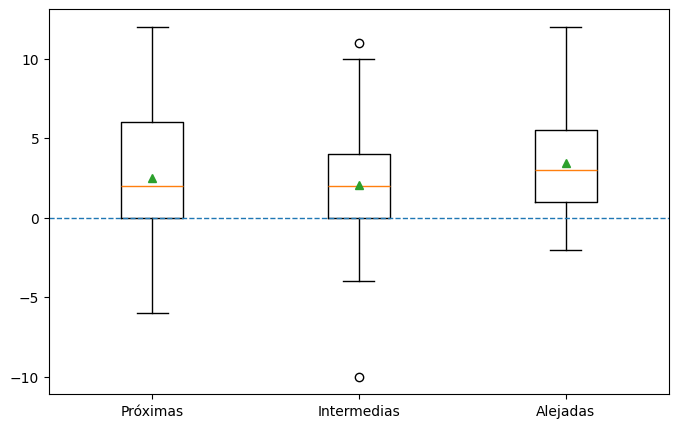

In [83]:
import matplotlib.pyplot as plt

orden = ["Próximas", "Intermedias", "Alejadas"]

datos_boxplot = [
    df_q_1min.loc[
        df_q_1min["Grupo_distancia"] == grupo, "+/-"
    ]
    for grupo in orden
]

plt.figure(figsize=(8, 5))

plt.boxplot(
    datos_boxplot,
    tick_labels=orden,
    showmeans=True
)

plt.axhline(0, linestyle="--", linewidth=1)

**EJE X :** tengo los 3 grupos

**EJE Y:** el rendimiento mediante +-

**caja ->** concentra parte de los valores, la linea dentro de ella es la mediana , los bigotes son la dispersion y los puntos de fuera son los valores extremos.

con showmeans true -> sale la media (triangulo)

**interpretacion:**  las 3 cajas se solapan bastante, se ve rendimientos positivos y negativos en zonas casi similares independientemente del grupo al que pertenezca

**ojo! el grupo alejadas** -> está algo + desplazado hacia los valores positivos y la media es mayor . ( lo que salía antes  donde tenia mayor +- medio)

aunque no existe una separacion clara entre los 3 grupos -> como vi antes p=0,3595 > 0,05 con el Kruskal Wallis

**conclusion:**
el boxplot muestra un amplio solapamiento en distribucion del +-

los quintetos formados por parejas con perfiles ofensivos + alejados presentan un rendimiento medio superior

no se ve una separacion clara entre las distribuciones -> concuerdad con el KW

**CONCLUSION FINAL : la diversidad ofensiva mejora el rendimiento del quinteto?**

**hipotesis inicial: la mayor diversidad de perfiles ofensivos dentro de un quinteto podría estar relacionada con un mejor rendimiento.**

aunque descriptivamente los quintetos con parejas + alejadas mostraron un +- medio superior, las pruebas estadisticas que he hecho no proporcionan una evidencia suficiente para confirmar dicha relacion.

-> la distancia ofensiva, considerada de forma aisladaa, no parece explicar el rendimiento de los quinttos en la muestra.

El analisis de Pearson + Spearman tampoco demostró una asociacion lineal significativa entre la distancia media de las parejas y el +-. Incluso al eliminar los intervalos inferiores a 1 min los resultaron siguieron = .

Por ultimo, los quintetos se clasificaron en 3 grupos segun la distancia ofensiva: proxima, intermedia y alejada. Aunque el grupo de alejadas presentó el mayor +- medio , la prueba del kruskal Wallis tampoco encontró eviidencias entre los 3 grupos.


----> **la diversidad ofenesiva medida unicamente mediante la distancia entre los perfiles de las parejas no es suficiente para explicar por sí sola el rendimiento del quinteto**



y lo que me lleva a peguntarme **¿para qué sirve entonces?**

no he intentado demostrar que Lennard-Jones preduce qué quinteto es mejor.

Se ha construido una interpretación de las parejas como elementos dentro del espacio ofensivo + estudiar sus distancias + relacionarlas esa estructura con los perfiles ofensivos mediante ML. Y he comprobado si esas distancias tenían una traducción en el rendimiento real de los quintetos.


entonces:

existe estructura en el espacio ofensivo? si

esa estructura coincide con la similitud del kmeans? si

una mayor distancia implica mejor rendimiento? los datos no me dan evidencias suficientes para afirmarlo

------------------------------------------------------- 0 -------------------------------

**importante!!!!**

En una 1º aprox se usó el +- como medida del rendimiento de cada quinteto. Se estudió su relación con la distancia media de las parejas mediante Pearson y Spearman y , luego  se comapararon los grupos de distancia mediante Kruskal-Wallis.


**Sin embargo, el +- es una medida acumulativa y depende del tiempo que el quinteto permanece en pista.** Ejemplo: un +5 obtenido en 2 min no representa el mismo ritmo de rendimiento que un +5 obtenido en 10 min. Aunque al inicio se eliminaron los intervalos inferiores a 1 min para reducir la influencia de periodos muy cortos, este filtro no elimina completamente el efecto de la duración.

**por este motivo -> se realiza ahora una segunda validacion** normalizando el +- por el tiempo de juego con : +- / min = +- / minutos . Así puedo comparar el rendimiento de los quintetos en una escala temporal comun.

La distancia media describe el nivel genral de separacion entre las parejas, pero no informa sobre cómo se distribuyen esas 10 distancias dentro del equilibrio. Por ello, **se va a calcular tambien la** **desviacion tipica de distancias como medida complementaria de heterogeneidad.**

**1º validacion con +- -> detecto la influencia del tiempo -> normalizo el rendimiento -> incorporo la desviacion tipica -> vuelvo a contrastar la hipotesis**

--------------------------------0------------------------------

**PASOS A SEGUIR EN LA AMPLIACION**

- NORMALIZAR EL RENDIMIENTO ; calcular el +- por minuto para corregir el tiempo en pista

- REPETIR LA VALIDACION estudiar la distancia_media frente a +- por minuto con grafica + Pearson + Spearman

- CALCULAR LA DESVIACION TIPICA DE LAS DISTANCIAS  medir cuanto varian entre si las 10 parejas del quinteto

- NUEVA VALIDACION estudiar Desviacion tipica frente a +- por minuto con grafica + Spearman + Pearson

-COMPARAR GRUPOS  clasificar los quintetos segun su heterogeneidad y comprobar si existen diferencias de rendimiento

- CONCLUSION FINAL determinar qué nos dicen conjuntamente DISTANCIA MEDIA + HETEROGENIDAD + RENDIMIENTO NORMALIZADO

------------------------ AMPLIACION ------------------------------

**NORMALIZACION DEL RENDIMIENTO : + / - POR MINUTO**

**es comparable un +5 conseguido en 2 min con un +5 conseguido en 10 min ?** No del todo. El + / - es acumulativo: cuanto mas tiempo permanece un quinteto en pista, mas tiempo tiene para aumentar o disminuir su diferencial -> por eso introducir la medida del rendimiento

**que problema tiene utilizar solamente el +-?** no tiene en cuenta cuanto tiempo estuvo el quinteto en pista

**cómo puedo hacer + comparables quintetos que han jugado tiempos diferentes?** normalizando el +- por los minutos jugados

**que quiero medir ahora?** el ritmo de generacion del diferencial -> cuanto +- obtiene el quinteto por cad minuto de juego

ojo!!! por que mantego el filtro de >=1 min ? sigo con df_q_1min xk normalizar por tiempo tiene un inconveniente : los intervalos extremadamente cortos puede gnerar valores x min exagerados



1º cojjo el +- de cada intervalo y lo divido entre sus minutos -> muestro quintetos , minutos ,  +- original y +- por minutos para comprobar que tiene sentido el calculo

In [84]:
#diferencial por minuto
df_q_1min["PlusMinus_min"] = (
    df_q_1min["+/-"] / df_q_1min["Minutos"]
)
#comprobacin
df_q_1min[
    ["Quinteto_J", "Minutos", "+/-", "PlusMinus_min"]
].head(10)

,Quinteto_J,Minutos,+/-,PlusMinus_min
0,"[J11, J9, J10, J1, J7]",4.833333,12,2.482759
3,"[J6, J11, J9, J1, J7]",1.550000,6,3.870968
4,"[J2, J11, J9, J1, J7]",1.816667,2,1.100917
6,"[J2, J5, J6, J9, J1]",1.716667,5,2.912621
7,"[J2, J5, J4, J6, J3]",3.366667,6,1.782178
8,"[J4, J6, J10, J3, J7]",2.816667,10,3.550296
9,"[J11, J9, J10, J1, J7]",1.266667,1,0.789474
11,"[J2, J4, J6, J3, J7]",3.883333,3,0.772532
13,"[J5, J11, J12, J1, J7]",1.333333,-2,-1.500000
14,"[J5, J11, J9, J12, J1]",2.533333,7,2.763158


el primer quinteto  9 / 3,75 = +9

el quinteto de +7 con 1,4167 minutos -> 7 / 1,4167 = +4,94 -> no solo consiguió +7 sino que se que durante ese intervalo generó aprox +4,94 ptos de diferencial por minuto

-> de esta forma el rendimiento representa el diferencial genarado por unidad de tiempo y me permite una comparacion + homogenea entre quintetos

----0---

**DISTANCIA MEDIA VS  + / -   / MIN** ---> GRAFICA

**hay una relacion entre la distancia ofensiva de las parejas q forman un quinteto y su rendimiento una vez corregido x el tiempo que permanece en pista?**

ojo! antes estudiaba si la distancia_media de las 10 parejs estaba relacionado con el +- , ahora -> hago la misma medida ofensiva pero sustituyo el rendimiento bruto por el nuevo +- / min

**los quintetos formados x perfiles ofensivos son + similares o + diferentes presentan un mejor ritmo de rendimiento?**

EJE X : distancia media , hacia la izq -> parejas ofensivamente + proximas , hacia la drcha -> parejas ofensivamente + alejadas

EJE Y : +- / MIN , arriba 0 -> rendimiento positivo por min, debajo -> negativo

In [85]:
import matplotlib.pyplot as plt
import numpy as np

cada punto -> es un intervalo de un quinteto de al menos 1 minuto

linea continua -> es la tendecia general de los datos

linea horizontal discontinua en 0 separa el rendimiento positivo y el negativo

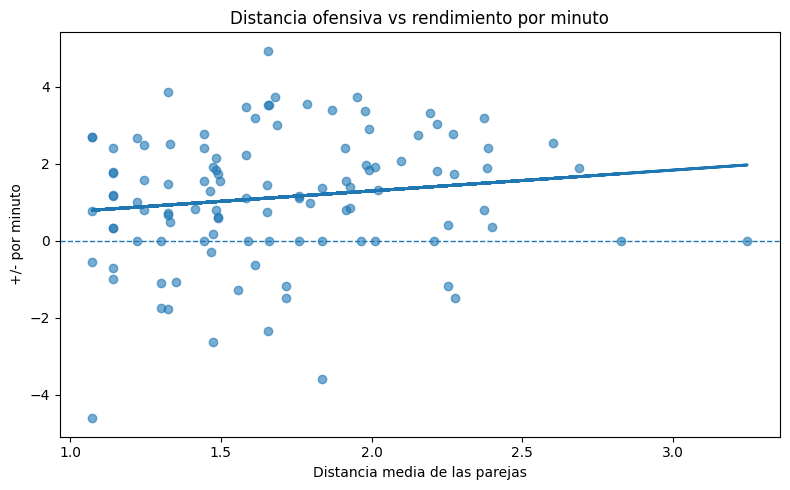

In [86]:
plt.figure(figsize=(8, 5))

#pts reales
plt.scatter(
    df_q_1min["Distancia_media"],
    df_q_1min["PlusMinus_min"],
    alpha=0.6
)

#linea de tendencia
x = df_q_1min["Distancia_media"]
y = df_q_1min["PlusMinus_min"]

m, b = np.polyfit(x, y, 1)

plt.plot(
    x,
    m*x + b,
    linewidth=2
)

#liinea de rendimiento neutro
plt.axhline(0, linestyle="--", linewidth=1)

plt.xlabel("Distancia media de las parejas")
plt.ylabel("+/- por minuto")
plt.title("Distancia ofensiva vs rendimiento por minuto")

plt.tight_layout()
plt.show()

**en el eje x** , mas a la izquierda son las parejas de quinteto que tienen en promedio perfiles ofensivos mas proximos y mas a la derecha las parejas representan mayor distancia ofensiva media

**la linea de tendencia sube ligeramente** , a mayor distancia media entre los perfiles ofensivos de las parejas, el +/ - por minuto tiende a aumentar ligeramente

**los puntos están muy dispersos alrededor de la linea de tendencia** -> para distancias similares hay rendimientos muy distintos , tanto positivos como negativos

en la distancia 1,5 - 2 hay quintetos ocn valores positivos y negativos muy altos , ceercanos a cero y tambien negativos

todavia no puedo decir que existe una relacion , se ve una tendencia ligeramente positiva , a simple vista no parece una relacion fuerte porque hay bastante dispersion . No puedo decir que a mayor distancia produce mejor rendimiento

In [87]:
ruta_graficas = "/content/drive/MyDrive/TFG_UGR/Proyecto_ML_Parejas_UGR"

plt.savefig(
    ruta_graficas + "/distancia_media_vs_plusminus_min.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

**PEARSON Y SPEARMAN**

pearson -> existe una relacion lineal ?

spearman -> existe una relacion monotona? si al aumentar una variable tiende generalmente a aumentar / disminuir la otra?

tengo que importar las pruebas estadisticas

In [88]:
from scipy.stats import pearsonr, spearmanr

cojo las dos variables que voy a comparar , distancia media  y el +- por minuto del quinteto

r -> coeficiente de pearson  : -1 <= r < = +1

si es cerca de +1 relacion positiva fuerte

si es cerca de -1 relacion negativa fuerte

si es cerca a 0 poco o ninguna relacion lineal

p pearson -> es el pvalor para ver la evidencia estadistica de la asociacion

In [89]:
x = df_q_1min["Distancia_media"]
y = df_q_1min["PlusMinus_min"]

#Pearson
r, p_pearson = pearsonr(x, y)

#Spearman
rho, p_spearman = spearmanr(x, y)

rho es el coeficiente de spearmean y pspearman su pvalor , mira si al aumentar la distancia , el rendimiento tiende generalmente a aumentar o disminuir sin exigir una relacion lineal

In [90]:
print("PEARSON")
print("r =", round(r, 3))
print("p-valor =", round(p_pearson, 4))

print("\nSPEARMAN")
print("rho =", round(rho, 3))
print("p-valor =", round(p_spearman, 4))

PEARSON
r = 0.14
p-valor = 0.1454

SPEARMAN
rho = 0.172
p-valor = 0.0732


con pearson r=0,14 y pvalor = 0,1454 asociacion lineal debil -> cuando aumenta la distancia media entre las parejas el +- por minuto tiende ligeramente a aumentar ( la pendiente ascendente de la grafica)

pero p=0,1454 > 0,05  -> no hay evidencia estadistica significativa de una relacion lineal


son spearman rho= 0,172 y p= 0.0732 positiva y debil  0,0732 > 0,05  tampoco puede considerarse significativo. Existe una tendencia positiva debil que no alcanza sigfnificacion estadistica

**con el +- bruto practicamente no se encuentra asociacion y al usar +- por minuto ahora aparecen coeficientes positivos r=0,140 y rho= 0,172 -> no alcanzan significacion estadistica al nivel del 5% ->  normalizar por tempo modifica la imagen que se obtiene , aunque la evidencia sigue sin ser suficiente para confirmar relacion**

----0-----------

**DESVIACION TIPICA**

ya no me pregunto que distancia media tienen las parejas ? sino que me pregunto ¿ las 10 parejas que forman un quinteto tienen distancias parecidas entre si o existe mucha heterogeneidad entre ellas?

**que quiero saber?** cada quinteto tiene 5 jugadoras -> 10 parejas -> 10 distancias . hasta ahora lo hacia con distancia media pero dos quintetos podrian tener una distancia media parecida y estar construidos de maneras muy diferentes

**que hara la desviacion tipica? sigma = sqrt( 1/ N sumatoria (di - d) ^2 )**

desviacion tipica baja -> las 10 distancias son parecidas entre si -> estructura de distancias mas homogenea

desviacion tipica alta -> las distancias son muy diferentes entre si -> estructura de distancias mas heterogenea

podria aparecer un quinteto con distancia media alta y desviacion tipica baja -> todas sus parejas estan alejadas pero aproximadamente a distancias similares

**hasta ahora parto de un quinteto de 5 jugadoras , que hacen 10 parejas , cada una de estas 10 parejas es un punto en el espacio ofensivo ( aro /min, media / min , triple /min y pb/min ) -> por lo que tengo 10 pts en el espacio ofensivo**

Se calcula la distancia entre esos ptos -> 45 distancias  

ejemplo : j1 - j2  <-> j1-j3  : 1 distancia , j1-j2 <-> j1-j4 : otra distancia ... y asi hasta 45

**antes** habia cogido esas 45 distancias  y hacia la media (cuanto estan separados en general los perfiles de pareja de ese quinteto) -> Distancia_media

**qué añado ahora** : uso esas 45 distancias  pero en lugar de calcular la distancia media ahora hago tambien la desviacion tipica  -> las 45 distancias son bastantes parecidas entre si o hay mucha variacion entre ellas ?

**entonces.... que hace cada uno ?**

la distancia media -> cuanto estan separados en general los perfiles de pareja?

la desviacion tipica -> cuanto varian esas separaciones dentro del quinteto?

luego lo relaciono con +-  / min

In [91]:
def desviacion_distancias_quinteto(lista_parejas):

    #Busco las coordenadas de las 10 parejas
    coordenadas = [
        coords_parejas[normalizar_pareja(p)]
        for p in lista_parejas
    ]

    #Las convierto en un array
    coordenadas = np.array(coordenadas)

    #Calculo las 45 distancias entre las 10 parejas
    distancias = pdist(coordenadas, metric="euclidean")

    #Calculo la desviaciontipica de  45 distancias
    return np.std(distancias)

ahora creo una columna en el dataframe -> aplico la funcin a todos los quintetos

In [92]:
df_q_1min["Desviacion_distancias"] = (
    df_q_1min["Parejas"].apply(desviacion_distancias_quinteto)
)

ahora cada intervalo tiene su propia desviaciontipica

**TABLA** distancia media  desviacion de distancias y +- / min

desviacion pequeña -> las 45 distancias tienen poca variabilidad

desviacion grande -> las 45 distancias tienen mayor variabilidad



In [93]:
df_q_1min[
    [
        "Quinteto_J",
        "Distancia_media",
        "Desviacion_distancias",
        "PlusMinus_min"
    ]
].head(10)

,Quinteto_J,Distancia_media,Desviacion_distancias,PlusMinus_min
0,"[J11, J9, J10, J1, J7]",1.245619,0.481205,2.482759
3,"[J6, J11, J9, J1, J7]",1.324651,0.718514,3.870968
4,"[J2, J11, J9, J1, J7]",1.584706,0.766733,1.100917
6,"[J2, J5, J6, J9, J1]",1.989987,0.669164,2.912621
7,"[J2, J5, J4, J6, J3]",1.142926,0.377450,1.782178
8,"[J4, J6, J10, J3, J7]",1.786406,1.003490,3.550296
9,"[J11, J9, J10, J1, J7]",1.245619,0.481205,0.789474
11,"[J2, J4, J6, J3, J7]",1.073810,0.343527,0.772532
13,"[J5, J11, J12, J1, J7]",2.277714,1.280703,-1.500000
14,"[J5, J11, J9, J12, J1]",2.269894,1.171207,2.763158


ahora cada quinteto tiene 3 datos : distancia media -> cuanto estan separados , los 10 perfiles de pareja ; desviacion tipica -> cuanto varian entre si las 45 distancias ; +- / min -> rendimiento del equipo corregido por tiempo

el quinteto j2-j4-j6-j3-j7 tiene desviacion media de 1,074 y desviacion de 0,344 -> la desviacion es pequeña respecto a otros -> las 45 distancias presentan relativamente poca dispersion alrededor de su media

j2-j5-j4-j8-j9 -> distancia media 2,689 y desviacion de 1,131 -> tiene una distancia media mayor + desviacion tipicia mayor -> los perfiles estan, en promedio, mas separados y ademas las separaciones son mucho mas variables entre si

tambien aparece el mismo quinteto varias veces  j2-j5-j4-j6-j3 tiene siempre distancia 1,142926  y desviacion 0,337450 pero el +- cambia entre intervalos ---> es logico! la media y desvicacion describen la estructura ofensiva del quinteto , pero su rendimiento puede cambiar segun el intervalo del partido

entonces...**puedo cuantificar no solo la separacion media de los perfiles de parejas, sino tambien la variabilidad de esas separaciones?** -> si  porque tengo desviacion_distancias

calculo la desviacion tipica de las 45 distancias existentes entre los 10 perfiles de pareja de cada quinteto .-> esta variable complementa a la distancia media, asi puedo cuantificar cuanto varian entre si las separaciones dentro de la estructura ofensiva del quinteto

**GRAFICA** - DESVIACION TIPICA VS RENDIMIENTO POR MINUTO  

**ESA VARIABIABILIDAD DE LAS DISTANCIAS ESTA RELACIONADA CON EL RENDIMIENTO POR MINUTO DEL QUINTETO?**

Los quintetos cuya estructura de ditancias es mas uniforme o mas variable presentan diferencias en su rendimiento?

EJE X  desviacion distancias

izq. -> menor variabilidad de las 45 distancias

derecha -> mayor variabilidad


EJE Y : +- por minuto

por encima de 0 -> rendimiento positivo por minuto

por debajo de 0 -> rendimiento negativo por minuto

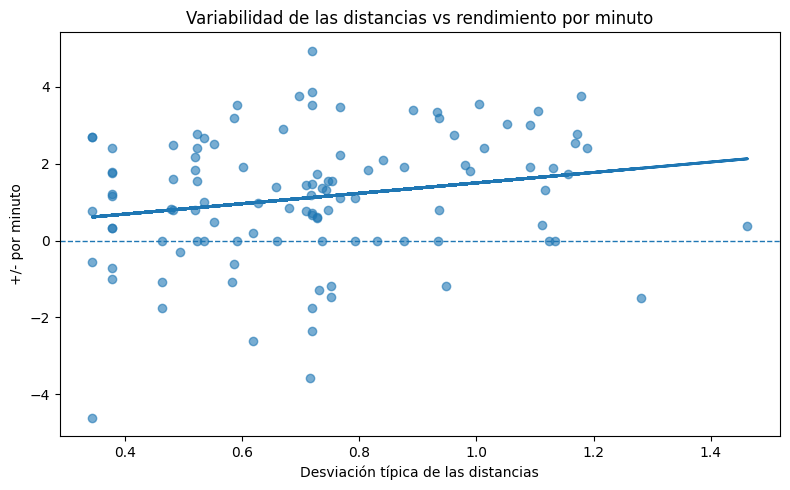

In [94]:
plt.figure(figsize=(8, 5))
#Variables
x = df_q_1min["Desviacion_distancias"]
y = df_q_1min["PlusMinus_min"]

#Pts reales
plt.scatter(x, y, alpha=0.6)

#linea de tendencia
m, b = np.polyfit(x, y, 1)
plt.plot(x, m*x + b, linewidth=2)

#liinea de rendimiento neutro
plt.axhline(0, linestyle="--", linewidth=1)

plt.xlabel("Desviación típica de las distancias")
plt.ylabel("+/- por minuto")
plt.title("Variabilidad de las distancias vs rendimiento por minuto")

plt.tight_layout()

#Guardar
plt.savefig(
    ruta_graficas + "/desviacion_distancias_vs_plusminus_min.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**cada pto es un intervalo de un quinteto de al menos 1 min**

eje x es la desviacion tipica de las 45 distancias

**la recta de tendencia sube** -> a medida que aumenta la variabilidad de las distancias entre los perfiles de pareja el rendimiento por minuto parece tender a aumentar

**en 0,7 hay mucha dispersion** , desde valores muy negativos a muy positivos

**la desviacion tipica si sola tampoco parece explicar claramente el rendimiento**

puedo hablar de quintetos heterogeneos ? puesssss con cuidado! porque una desviacion tipica alta significa que dentro del quinteto hay separaciones muy distintas entre los perfiles de pareja . eso ok!

quizas haya una tendencia positiva en una mayor heterogeneidad en las distancias entre los perfiles ofensivos de pareja cuando se asocia a un mayor rendimiento por minuto

**PEARSON + SPEARMAN**

PEARSON -> existe una relacion lineal entre heterogeneidad y rendimiento por minuto ?

spearman -> cuando aumenta la heterogeneidad, el rendimiento tiende generalmente a aumentar o a disminuir?

In [95]:
x = df_q_1min["Desviacion_distancias"]
y = df_q_1min["PlusMinus_min"]

#Pearson
r, p_pearson = pearsonr(x, y)

#Spearman
rho, p_spearman = spearmanr(x, y)

print("PEARSON")
print("r =", round(r, 3))
print("p-valor =", round(p_pearson, 4))
print("\nSPEARMAN")
print("rho =", round(rho, 3))
print("p-valor =", round(p_spearman, 4))

PEARSON
r = 0.202
p-valor = 0.0352

SPEARMAN
rho = 0.206
p-valor = 0.0316


**RESULTADOOOOOOOOOS DIFERENTEEEEES!!! A LOS DE ANTES!!**

**PEARSON** -> r =0,202 , **p= 0,0352**

**SPEARMAN** -> rho= 0,206 , **p= 0,0316**


**pearson** r=0,202  -> asociacion llineal positiva debil

cuando aumenta la variabilidad de las distancias  el +- por minuto tiende a aumentar ligeramente

**p=0,0352 < 0,5 -> SI HAY EVIDENCIA ESTADISTICAMENTE SIGNIFICATIVA DE UNA ASOCIACION LINEAL (USANDO EL NIVEL DE SIGNIFICACION DEL 5%)**

**spearman** -> rho = 0,206 -> asociacion positiva debil

**p=0,0316 < 0,5 -> SI HAY EVIDENCIA ESTADISTICA DE UNA ASOCIACION MONOTONICA POSITIVA**

**conclusion:** que pearson + spearman den resultados tan parecidos (0,202 y 0,206) da bastante coherencia al resultado

pero no fuerte! la asociacion es debil .

Se ha encontrado una asociacion positiva debil y estadisticamente significativa entre la variabilidad de las distancias de los perfiles de pareja y el rendimiento por minuto del quinteto.


**¿ que quiere decir esto?**  es interesante!!  porque diferencio dos cosas .

**distancia media vs +- por minuto**

pearson : p = 0,1454 ; Spearman : p= 0,0732  -> **no significativa **

**desviacion de distancia vs +- por minuto**

pearson : p= 0,0352 , spearman : p= 0,0316 -> **significativa al 5% aunque debil**

el rendimiento no parece estar relacionado de forma significativa con lo alejado que estan , en promedio, los perfiles de pareja; sin embargo, si aparece una asociacion debil con la variabilidad interna de esas distancias

se analiza las parejas que forman cada quinteto y las situo en el espacio ofensivo segun sus caracateristicas de (aro/min, triple /min....) despues miro si esos perfiles estan mas juntos o mas separados entre si

**conclusion:** no parece que por estar las parejas mas juntas o mas separadas en el espacio ofensivo el quinteto vaya a rendir mejor o peor , eso por si solo no nos dice demasiado.

Lo interesante aparece cuando miro cómo están repartidas esas parejas : si dentro del mismo quinteto tengo algunas parejas muy parecidas y otras bastante diferentes ->  hay mas variedad en las distancias aparece una pequeña relacion con un mayor rendimiento por minuto .

-----------0------------

**COMPROBAR GRUPOS SEGUN HETEROGENEIDAD**

**Y si separo los quintetos en grupos segun esa variabilidad??**

con los quintetos con poca / media / mucha variabilidad entre las distancias de sus parejas muestran diferencias en el rendimiento por minuto?

cojo desviacion_distancias y divido en 3 GRUPOS!!

**BAJA VARIABILIDAD** las 45 distancias entre los perfiles de pareja son relativamente parecidas entre si

**VARIABILIDAD MEDIA** situacion intermedia

**ALTA VARIABILIDAD** dentro de un quinteto hay distancias pequeñas y otras mayores

luego comparo con +- -> tabla -> grafico boxplot -> kruskal-wallis (comprobar si las diferencias entre grupos tienen respaldo estadistico )

**recuerdo para mi : las 45 distancias vienen de que en cada 10 parejas hay 45 distancias (10 2) -> 10 x 9 /2 = 45  (combinaciones) entre los perfiles ofensivos de esas 10 parejas . distacia que hay de j1-j2 con j1-j3, j1-j2 con j1-j4**

vale, ya se que una mayor variedad de distancias tiene cierta relacion con el rendimiento.... pero ¿ se ve tambien cuando separo los quintetos segun tengan baja, media o alta variabilidad?

**CREAR GRUPOS SEGUN LA VARIABILIDAD DE LAS DISTANCIAS**

con cut -> ordeno los quintetos segun su desviacion distancias y los reparto en 3 grupos con aprox el mismo numero de observaciones

In [96]:
df_q_1min["Grupo_variabilidad"] = pd.qcut(
    df_q_1min["Desviacion_distancias"],
    q=3,
    labels=["Baja", "Media", "Alta"]
)

# Comprobamos cuántos casos hay en cada grupo
print(df_q_1min["Grupo_variabilidad"].value_counts().sort_index())

Grupo_variabilidad
Baja     37
Media    35
Alta     37
Name: count, dtype: int64


37+35+37 = 109 observaciones porque tengo 109 intervalos

he ordenado los intervalos segun la desviacion tipicia de sus 45 distancias y las he dividido aprox en 3 tercios .

? **como rinden los quintetos del grupo de baja / media / alta variabilidad?**

tengo que **calcular el +- por minuto medio y mediano por cada grupo**

media-> me dirá el rendimiento promedio de cada grupo

mediana -> evita que algun intervalo con +- por minuto me pueda engañar si es muy extremo

In [97]:
#rendimiento 3 grupos
resumen_variabilidad = (
    df_q_1min
    .groupby("Grupo_variabilidad", observed=True)
    .agg(
        N=("Grupo_variabilidad", "size"),
        Desviacion_media=("Desviacion_distancias", "mean"),
        PlusMinus_min_medio=("PlusMinus_min", "mean"),
        PlusMinus_min_mediana=("PlusMinus_min", "median")
    )
    .round(3)
)

display(resumen_variabilidad)

,N,Desviacion_media,PlusMinus_min_medio,PlusMinus_min_mediana
Grupo_variabilidad,,,,
Baja,37,0.460,0.824,0.833
Media,35,0.699,0.838,0.845
Alta,37,1.006,1.697,1.905


ojo!!!! los grupos de baja y media variabilidad rinden casi igual ( 0,824 y 0,838) pero el de alta no! rinde a 1,697 puntos de +- por minuto

y la mediana también sube para el de alta hasta 1,905

cuando dentro de un quinteto las distancias entre los perfiles de parejas son muy variadas (unas parejas se parecen mucho y otras son bastantes diferentes) -> se ve descriptivamente un rendimiento por minuto mayor

encaja con -> una asociacion positiva debil entre la variabilidad de las distancias y el rendimiento pero aun no puedo concluir que los tres grupos sean estadisticamente diferentes

**KRUSKAL - WALLIS**

esta diferencia del grupo de alta variabilidad es suficiente consistente estadisticamente o podria deberse a la variabilidad de la muestra?

**si p< 0,05** hay evidencias de que al menos 1 de los 3 grupos presenta una distribución de rendimiento diferente

**si p> 0,05** aunque visualmente vea diferencias, no tengo evidencias estadisticas suficientes para afirmar que los grupos difieren



In [98]:
from scipy.stats import kruskal

In [99]:
#rendimiento de cada grupo
baja = df_q_1min.loc[
    df_q_1min["Grupo_variabilidad"] == "Baja",
    "PlusMinus_min"
]

media = df_q_1min.loc[
    df_q_1min["Grupo_variabilidad"] == "Media",
    "PlusMinus_min"
]

alta = df_q_1min.loc[
    df_q_1min["Grupo_variabilidad"] == "Alta",
    "PlusMinus_min"
]

In [100]:
# Prueba de Kruskal-Wallis
H, p_kw = kruskal(baja, media, alta)

print("Kruskal-Wallis")
print("H =", round(H, 3))
print("p =", round(p_kw, 4))

Kruskal-Wallis
H = 6.843
p = 0.0327


**p < 0,05 entonces encuentro diferencias estadisticamente significativas entre los 3 grupos!!!!**

cuando separo los quintetos segun la variabilidad que existe entre las 45 distancias de sus parejas, el rendimiento por minuto no se comporta = en los 3 grupos

en la tabla -> el grupo de alta variabilidad tenia un +- por minuto medio de 1,697 frente a 0,824 y 0,838 en baja y media

KW! no me dice todavia entre que grupos está la diferencia!! ojo!!! pueede ser alta-baja , alta - media....etc

**RESULTADOS**

**correlaciones :** mayor variabilidad -> asociacion positiva debil con rendimiento p< 0,05

**KRUSKAL-wallis** , al dividir por niveles de variabilidad -> existen diferencias entre grupos p= 0,0327

**ENTRE QUE GRUPOS TENGO LA DIFERENCIA?**

aplico la correeccion de Bonferroni -> para no encontrar una diferencia "significativa" simplemente por hacer varios test

como voy a hacer 3 pruebas estadisticas diferentes , hay mayor posibilidad de que alguna salga p< 0,05

bonferroni -> es una forma sencilla de ser estricto para evitar eso "p_corregido" = p*3  multiplico por 3 porque voy a hacer 3 comparaciones

**kruskal-wallis** hay alguna diferencia entre los 3 grupos ?

**mann-whitney** , entre que dos grupos esta la diferencia?

**bonferroni**  como lo estoy haciendo varias comparaciones, corrijo los p-valores para ser mas prudente y **reducir falsos positivos**

In [101]:
from scipy.stats import mannwhitneyu

comparaciones entre los grupos : mann-whitney y correcion de bonferroni

mann-whitney me compara 2 grupos a la vez a diferencia que kurskal-wallis que lo hacia con los 3 grupos a la vez

quiero hacer : baja - media, baja - alta , media -alta

asi localizo de donde viene la diferencia que se vió en kruskalwallis

In [102]:
comparaciones = [
    ("Baja", baja, "Media", media),
    ("Baja", baja, "Alta", alta),
    ("Media", media, "Alta", alta)
]

for nombre1, grupo1, nombre2, grupo2 in comparaciones:

    U, p = mannwhitneyu(
        grupo1,
        grupo2,
        alternative="two-sided"
    )

    # Corrección de Bonferroni: hacemos 3 comparaciones
    p_corregido = min(p * 3, 1.0)

    print(f"{nombre1} vs {nombre2}")
    print("U =", round(U, 3))
    print("p =", round(p, 4))
    print("p corregido =", round(p_corregido, 4))
    print("--------------------")

Baja vs Media
U = 662.5
p = 0.8702
p corregido = 1.0
--------------------
Baja vs Alta
U = 462.0
p = 0.0163
p corregido = 0.0489
--------------------
Media vs Alta
U = 461.5
p = 0.0364
p corregido = 0.1093
--------------------


**si p< 0,05 es estadisticamente significativo**

**si p >= 0,05 NO estadisticamente significativo**

baja vs media -> p corregido = 1 -> no significativo

baja vs alta -> p corregido = 0,0489 si significativo

media vs alta -> p corregido = 0,1093 no significativo

**baja y media practicamente no se diferencia**. Sus rendimientos medios en la tabla eran casi iguales (0,824 y 0,838)

pero! **en baja vs alta -> 0,0489 < 0,05 incluso despues de bonferroni**
-> evidencia de una diferencia entre el rendimiento de los grupos de baja y alta variabilidad


cuando los quintetos tienen poca variabilidad entre las distancias de sus parejas y cuando tienen mucha, si aparece una diferencia en su rendimiento.
(poca variabilidad  y distancias pequeñas seria 1-1,1-0,9.... poca variabilidad pero los pts estan bastantes alejados : 2,8-2,9-3.... alta variabilidad porque tengo distancias muy pequeñas y otras muy grandes : 0,5-0,7-2,1-3...) Los quintetos con mayor variedad entre estas distancias muestran una asociacion cn el rendimiento

los de alta variabilidad mostraron mayor rendimiento por minuto en la muestra.

**y como 0,489 está muy cerca del limite 0,05 se observa una diferencia estadisticamente significativa entre los grupos de baja y alta variabilidad**


**llegado a este punto...y esto para qué le sirve al entrenador?** seria una herramienta complementaria para estudiar como construir quintetos. Ejemplo: se podria detectar que determinados quintetos combinan parejas con perfiles ofensivos muy similares junto con otras mucho mas diferentes , y ver que estructura se ha asociado con un mejor rendimiento en los partidos analizados.

-> no solo puedo mirar quienes son las 5 jugadores o cuanto anota cada 1. Tambien puedo estudiar como se complementan entre si las distintas parejas que estan dentro de ese quinteto.

**GRAFICA DE LOS 3 GRUPOS**

COMO SE DISTRIBUYE EL RENDIMIENTO POR MINUTO EN LOS QUINTETOS CON BAJA /MEDIA / ALTA VARIABILIDAD?  --> BOXPLOT

quiero ver si los quintetos con baja/ media / alta vaariabilidad en las distancias de sus perfiles de pareja muestran compartamientos diferentes en rendimientos x min

In [103]:
import matplotlib.pyplot as plt

datos boxplot me coge el +-min de los quintetos -> separa en los 3 grupos-> es para preparar las 3 cajas con los rendimientos de cada grupo.

con cada caja puedo ver como estan repartidos los valores del rendimiento -> la linea de dentro de la caja es la mediana , (showmeans true ) -> la media

**plt axhline (0, linestyle=.... dibuja una linea horizontal en +- por minuto =0**

**por encima de 0 ->** balance positivo durante esos intervalos

**por debajo de 0 ->** balance negativo

/tmp/ipykernel_3789/49285682.py:22: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


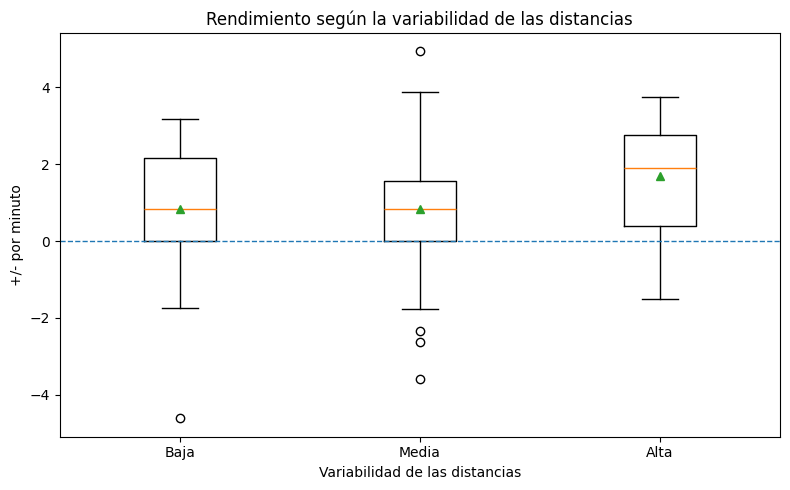

In [104]:
#separo el rendimiento de los 3 grupos
datos_boxplot = [
    df_q_1min.loc[
        df_q_1min["Grupo_variabilidad"] == "Baja",
        "PlusMinus_min"
    ],

    df_q_1min.loc[
        df_q_1min["Grupo_variabilidad"] == "Media",
        "PlusMinus_min"
    ],

    df_q_1min.loc[
        df_q_1min["Grupo_variabilidad"] == "Alta",
        "PlusMinus_min"
    ]
]

#grafica
plt.figure(figsize=(8, 5))

plt.boxplot(
    datos_boxplot,
    labels=["Baja", "Media", "Alta"],
    showmeans=True
)

plt.axhline(0, linestyle="--", linewidth=1)

plt.xlabel("Variabilidad de las distancias")
plt.ylabel("+/- por minuto")
plt.title("Rendimiento según la variabilidad de las distancias")

plt.tight_layout()

# GuardO
plt.savefig(
    ruta_graficas + "/boxplot_variabilidad_rendimiento.png",
    dpi=300,
    bbox_inches="tight"
)

me interesa el de alta!!! la caja está mas arriba y la mediana ronda el 1,9 de +- por minuto

baja y media está la medianas unos 0,8 aprox.

-> los triangulos son las medias que son parecidas , aunque en la alta esta por encima

los ptos de fuera de las cajas son los intervalos de +- por minuto que son bastantes diferente dle comportamiento habitual del grupo . Alta no presenta ningun punto fuera mientras baja y media si , me viene bien el haber usado kruskal-wallis y las medianas por estos datos tan extremos

los quintetos con baja y media variabilidad entre las distancias de sus parejas tienen rendimientos bastantes parecidos

Cuando veo los quintetos de alta variabilidad -> el rendimiento por minuto tiende a ser mayor


conclusion: lso quintetos con alta variabilidad en las distancias entre perfiles de pareja presentan un mayor rendimiento por minuto. Las diferencias globales fueron significativas, observandose tras la correccion de Bonferroni una diferencia significativa entre los grupos de baja ya alta variabilidad.

------------0-------------

que he descubierto y para qué sirve? no he encontrado que simplemente tener los perfiles de pareja mas separados de media implique un mejor rendimiento . Lo que sí aparece relacionado con el rendimiento es la variabilidad de esas distancias dentro del quinteto

-> parece mas interesante estudiar como se combinan perfiles de parejas diferentes dentro de las 5 jugadoras